# Lecture 15 — Measuring interactions in animal groups

We have already seen that simple interaction rules can generate complex and diverse collective behaviors. But, given a real-world example of a bird flock or fish school, how can you tell from experiments what interaction rules the animals use?

This companion follows the HTML lecture: measured fish responses, collective decisions and sensing, locust mechanisms, bird alignment dynamics, and fly density prediction. Published figures remain experimental evidence; illustrative calculations are identified explicitly. Run all cells in the repository’s `swarming-course` environment.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.special import gammaln, logsumexp
from scipy.optimize import minimize, brentq
from scipy.interpolate import CubicSpline
from scipy.signal import savgol_filter

ROOT = Path.cwd().parent if Path.cwd().name == 'lectures' else Path.cwd()
DATA = ROOT / 'data'
OUT = DATA / 'collective-motion'
OUT.mkdir(exist_ok=True)
COLORS = dict(ink='#f1ece2', amber='#f2b33d', blue='#67b7dc', red='#ed8170', green='#79be9e', muted='#aaa18e')
plt.rcParams.update({'figure.facecolor':'#12110e', 'axes.facecolor':'#12110e',
                     'text.color':COLORS['ink'], 'axes.labelcolor':COLORS['ink'],
                     'xtick.color':COLORS['muted'], 'ytick.color':COLORS['muted'],
                     'axes.edgecolor':'#797264', 'font.size':13, 'axes.labelsize':14,
                     'figure.figsize':(10.5,4), 'savefig.facecolor':'#12110e',
                     'axes.spines.top':False, 'axes.spines.right':False})
packet = {'schema':1, 'lecture':15, 'colors':COLORS, 'source_kind':{'fish':'measured trajectories', 'flies':'measured bin occupancies', 'birds':'measured 3D trajectories', 'midges':'measured 3D track fragments'}}
rng = np.random.default_rng(56715)

## Polarization with variable speeds

HTML slide 3.

$$
\Phi=\left|\frac1N\sum_i\hat{\mathbf e}_i\right|,
\qquad \Phi_v=\frac{|\sum_i\mathbf v_i|}{\sum_i|\mathbf v_i|}.
$$

Two animals move right at speed 1; one moves left at speed 8. Heading polarization is $1/3$, while speed-weighted polarization is $0.6$.

In [2]:
def order_parameters(positions, velocities):
    speeds = np.linalg.norm(velocities, axis=-1)
    valid = np.isfinite(velocities).all(axis=-1) & (speeds > 1e-9)
    if not valid.any():
        return dict(phi=np.nan, phi_v=np.nan, rotation=np.nan, count=0)
    p, v, speed = positions[valid], velocities[valid], speeds[valid]
    heading = v / speed[:, None]
    relative = p - p.mean(axis=0)
    radius = np.linalg.norm(relative, axis=-1)
    radial = relative / np.maximum(radius[:, None], 1e-12)
    circulation = np.cross(radial, heading) if p.shape[-1] == 3 else radial[:,0]*heading[:,1] - radial[:,1]*heading[:,0]
    return dict(phi=float(np.linalg.norm(heading.mean(axis=0))),
                phi_v=float(np.linalg.norm(v.sum(axis=0))/speed.sum()),
                rotation=float(np.abs(np.mean(circulation)) if p.shape[-1]==2 else np.linalg.norm(circulation.mean(axis=0))), count=int(valid.sum()))

example_p = np.array([[-1.,0.],[1.,0.],[0.,1.]])
example_v = np.array([[1.,0.],[1.,0.],[-8.,0.]])
assert np.isclose(order_parameters(example_p, example_v)['phi'], 1/3)
assert np.isclose(order_parameters(example_p, example_v)['phi_v'], 0.6)

## Tracking a pair of mosquitofish

HTML slides 7–9.

Forty pair trials, recorded at 40 frames/s. Positions are in mm.

Schaerf, Herbert-Read & Ward (2021), [article](https://doi.org/10.1098/rsif.2020.0925), [data](https://doi.org/10.6084/m9.figshare.14265787.v1).

In [3]:
fish_archive = np.load(DATA/'flocking/fish-pairs-2021.npz')
fish_trials = {key:fish_archive[key] for key in fish_archive.files}
fish_dt = 1/40
assert len(fish_trials)==40
assert all(a.ndim==3 and a.shape[1:]==(2,2) for a in fish_trials.values())

def valid_runs(mask, minimum=1):
    edges = np.diff(np.r_[False, mask, False].astype(int))
    return [(int(a),int(b)) for a,b in zip(np.flatnonzero(edges==1),np.flatnonzero(edges==-1)) if b-a>=minimum]

fish_summary = pd.DataFrame([{'trial':key,'frames':len(p),'both tracked':int(np.isfinite(p).all(axis=(1,2)).sum())} for key,p in fish_trials.items()])
fish_summary.head()

,trial,frames,both tracked
0,group_01,24100,12675
1,group_02,26826,12575
2,group_03,24693,12400
3,group_04,20278,12040
4,group_05,24581,13656


### Acceleration changes speed and direction

HTML slides 8, 10–12.

$$
\mathbf a=\dot v\,\hat{\mathbf e}+v\dot\vartheta\,\hat{\mathbf e}_\perp.
$$

Local cubic fits estimate derivatives within each continuous tracked interval. The angular-velocity comparison uses 11- and 21-frame windows; speeds below 5 mm/s are omitted.

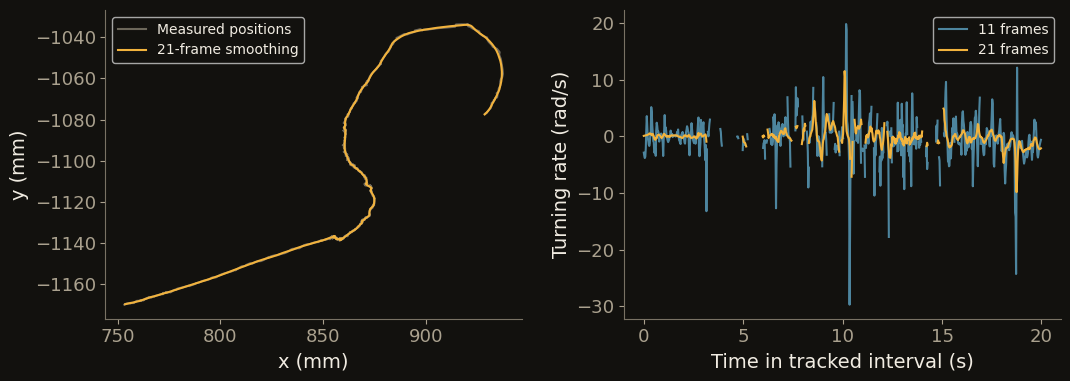

In [4]:
def planar_kinematics(positions, dt, window=21):
    smooth = savgol_filter(positions, window, 3, axis=0)
    velocity = savgol_filter(positions, window, 3, deriv=1, delta=dt, axis=0)
    acceleration = savgol_filter(positions, window, 3, deriv=2, delta=dt, axis=0)
    speed = np.linalg.norm(velocity, axis=-1)
    direction = velocity / np.maximum(speed[...,None], 1e-12)
    speeding = np.sum(acceleration*direction, axis=-1)
    turning = (velocity[...,0]*acceleration[...,1]-velocity[...,1]*acceleration[...,0])/np.maximum(speed**2,1e-12)
    # A near-stationary velocity has no reliable measured heading.
    turning=np.where(speed>=5,turning,np.nan)
    return smooth, velocity, acceleration, speed, speeding, turning

replays=[]
for key in list(fish_trials)[:3]:
    p=fish_trials[key]; a,b=max(valid_runs(np.isfinite(p).all(axis=(1,2)),minimum=100),key=lambda ab:ab[1]-ab[0])
    b=min(b,a+2400)
    raw=p[a:b]; sm,v,acc,speed,speeding,turning=planar_kinematics(raw,fish_dt)
    keep=np.arange(12,len(raw)-12,4)
    rows=np.column_stack(((a+keep)*fish_dt,raw[keep].reshape(len(keep),4),v[keep].reshape(len(keep),4),turning[keep]))
    replays.append({'trial':key,'rows':rows,'dt':0.1,'source_start_frame':a,'position_units':'mm'})
packet['fish_replays']=replays

p=fish_trials['group_01']; a,b=max(valid_runs(np.isfinite(p).all(axis=(1,2)),minimum=100),key=lambda ab:ab[1]-ab[0]);p=p[a:min(b,a+800),0]
k11=planar_kinematics(p,fish_dt,11);k21=planar_kinematics(p,fish_dt,21)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(p[:,0],p[:,1],color=COLORS['muted'],alpha=.6,label='Measured positions')
ax[0].plot(k21[0][:,0],k21[0][:,1],color=COLORS['amber'],label='21-frame smoothing')
ax[0].set(xlabel='x (mm)',ylabel='y (mm)',aspect='equal');ax[0].legend(fontsize=10)
t=np.arange(len(p))*fish_dt
ax[1].plot(t,k11[-1],color=COLORS['blue'],alpha=.7,label='11 frames')
ax[1].plot(t,k21[-1],color=COLORS['amber'],label='21 frames')
ax[1].set(xlabel='Time in tracked interval (s)',ylabel='Turning rate (rad/s)');ax[1].legend(fontsize=10)
plt.tight_layout();plt.show()
kinematic_export={'time':t.copy(),'raw':p.copy(),'smoothed':k21[0],'velocity':k21[1],'acceleration':k21[2], 'turn11':k11[-1],'turn21':k21[-1]}

### Neighbor position in the focal fish's frame

HTML slides 9, 13–14.

$x$ points forward and $y$ points left. Encounter headings use the preceding 0.2 s of displacement; the turning response uses the next 0.2 s.

In [5]:
def body_coordinates(displacement, focal_velocity):
    e=focal_velocity/np.maximum(np.linalg.norm(focal_velocity,axis=-1,keepdims=True),1e-12)
    return np.stack((np.sum(displacement*e,axis=-1),-displacement[...,0]*e[...,1]+displacement[...,1]*e[...,0]),axis=-1)

def wrap_angle(angle):
    return np.arctan2(np.sin(angle),np.cos(angle))

# Features use the preceding 0.2 s of displacement. The response uses the next 0.2 s.
# Trial splits therefore do not share frames, and predictors do not use future positions.
fish_encounters=[]
hop=8
for trial,(key,p) in enumerate(fish_trials.items(),1):
    t=np.arange(hop,len(p)-hop,4)
    now=(p[t]-p[t-hop])/(hop*fish_dt)
    after=(p[t+hop]-p[t])/(hop*fish_dt)
    for focal in [0,1]:
        neighbor=1-focal
        displacement=p[t,neighbor]-p[t,focal]
        body=body_coordinates(displacement,now[:,focal])
        speed=np.linalg.norm(now[:,focal],axis=1)
        partner_speed=np.linalg.norm(now[:,neighbor],axis=1)
        heading=np.arctan2(now[:,focal,1],now[:,focal,0])
        future_heading=np.arctan2(after[:,focal,1],after[:,focal,0])
        delta=wrap_angle(np.arctan2(now[:,neighbor,1],now[:,neighbor,0])-heading)
        turn=wrap_angle(future_heading-heading)/(hop*fish_dt)
        speeding=(np.linalg.norm(after[:,focal],axis=1)-speed)/(hop*fish_dt)
        r=np.linalg.norm(body,axis=1)
        good=np.isfinite(np.column_stack((body,delta,speed,partner_speed,turn,speeding))).all(axis=1)&(r>5)&(r<180)&(speed>5)&(speed<300)&(partner_speed>5)&(partner_speed<300)
        for j in np.flatnonzero(good):
            fish_encounters.append((trial,int(t[j]),focal,body[j,0],body[j,1],r[j],delta[j],speed[j],partner_speed[j],turn[j],speeding[j]))
enc=np.array(fish_encounters)
assert len(enc)>1000
print(f'{len(enc):,} eligible encounters across {len(np.unique(enc[:,0]))} trials; overlapping observations remain grouped by trial.')

162,308 eligible encounters across 40 trials; overlapping observations remain grouped by trial.


### Mean turning around a neighbor

HTML slides 15–18.

$$
A_{\rm turn}(x,y)=\left\langle\dot\vartheta_i\mid x_{ij}=x,\ y_{ij}=y\right\rangle.
$$

The map averages the subsequent turning response at each relative neighbor position. Bins require at least 20 observations.

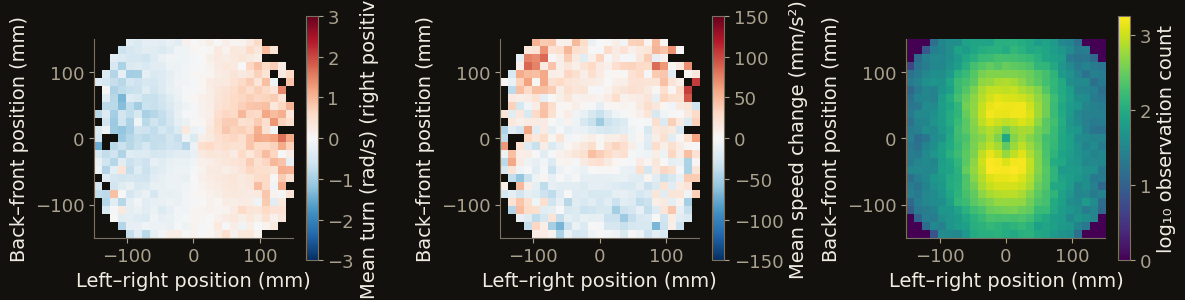

In [6]:
def response_map(x,y,values,edges,minimum=20):
    counts,_,_=np.histogram2d(y,x,bins=(edges,edges))
    total,_,_=np.histogram2d(y,x,bins=(edges,edges),weights=values)
    mean=np.divide(total,counts,out=np.full_like(total,np.nan),where=counts>=minimum)
    return mean,counts

map_edges=np.linspace(-150,150,26)
turn_map,map_counts=response_map(enc[:,3],enc[:,4],enc[:,9],map_edges)
speed_map,_=response_map(enc[:,3],enc[:,4],enc[:,10],map_edges)
fig,ax=plt.subplots(1,3,figsize=(12,3.8))
for axis,values,label,cm,lim in zip(ax,[turn_map,speed_map,np.log10(np.maximum(map_counts,1))],['Mean turn (rad/s)','Mean speed change (mm/s²)','log₁₀ observation count'],['RdBu_r','RdBu_r','viridis'],[3,150,None]):
    display_values=values[::-1,:].T
    if label=='Mean turn (rad/s)': display_values=-display_values
    artist=axis.imshow(display_values,origin='lower',extent=(-150,150,-150,150),cmap=cm,vmin=-lim if lim else None,vmax=lim,aspect='equal')
    axis.set(xlabel='Left–right position (mm)',ylabel='Back–front position (mm)');fig.colorbar(artist,ax=axis,shrink=.75,label=label+ (' (right positive)' if label=='Mean turn (rad/s)' else ''))
plt.tight_layout();plt.show()
packet['fish_maps']={'edges':map_edges,'turn':turn_map,'speeding':speed_map,'counts':map_counts,'eligible_observations':len(enc),'trials':40,'minimum_observations':20}

### Predicting turns in new fish trials

HTML slides 22–24.

Fit trials 1–30 and predict trials 31–40, with equal weight for each training trial.

Compare position/speed features with the same model plus two relative-heading terms.

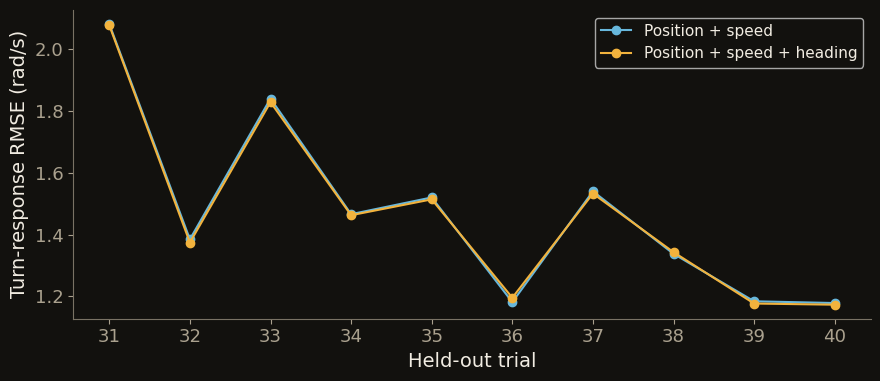

{'Position + speed': 1.471, 'Position + speed + heading': 1.468}


In [7]:
def response_features(encounters,include_heading=False):
    x,y,r=encounters[:,3],encounters[:,4],encounters[:,5]
    delta,speed,partner_speed=encounters[:,6],encounters[:,7],encounters[:,8]
    lateral=y/r;forward=x/r
    features=[np.ones(len(r)),lateral,lateral*np.exp(-r/35),lateral*forward,
              np.log(speed/50), (partner_speed-speed)/50]
    if include_heading:
        features += [np.sin(delta),np.sin(delta)*np.exp(-r/80)]
    return np.column_stack(features)

def weighted_ridge(x,y,trial_ids,ridge=1e-3):
    ids,counts=np.unique(trial_ids,return_counts=True)
    w=np.array([1/counts[np.searchsorted(ids,t)] for t in trial_ids])
    return np.linalg.solve(x.T@(w[:,None]*x)+ridge*np.eye(x.shape[1]), x.T@(w*y))

train=enc[:,0]<=30;test=~train
models={}
per_trial=[]
for name,heading in [('Position + speed',False),('Position + speed + heading',True)]:
    x=response_features(enc,heading);coef=weighted_ridge(x[train],enc[train,9],enc[train,0])
    prediction=x@coef
    errors=[]
    for trial in range(31,41):
        mask=enc[:,0]==trial
        errors.append(float(np.sqrt(np.mean((prediction[mask]-enc[mask,9])**2))))
        per_trial.append({'trial':trial,'model':name,'RMSE (rad/s)':errors[-1]})
    models[name]={'coefficients':coef,'rmse_by_trial':errors,'mean_trial_rmse':float(np.mean(errors))}
packet['response_models']=models
result=pd.DataFrame(per_trial)
fig,ax=plt.subplots(figsize=(9,4))
for name,c in zip(models,[COLORS['blue'],COLORS['amber']]):
    a=result[result['model']==name];ax.plot(a['trial'],a['RMSE (rad/s)'],'o-',label=name,color=c)
ax.set(xlabel='Held-out trial',ylabel='Turn-response RMSE (rad/s)',xticks=range(31,41));ax.legend(fontsize=11)
plt.tight_layout();plt.show()
print({name:round(v['mean_trial_rmse'],3) for name,v in models.items()})

### Variation between fish trials

HTML slides 17, 19, 23–24.

Calculate support and SEM across trial-specific maps. Compare similar and opposing headings; compare the two focal fish within trial 1.

The two 2 s examples have the smallest and largest test-window errors. Overall performance is summarized by the ten trial RMSEs.

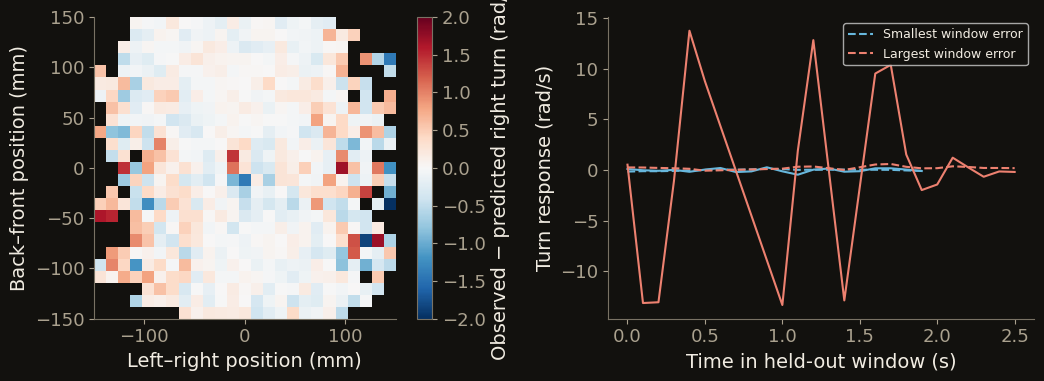

In [8]:
trial_maps=[]
for trial in range(1,41):
    e=enc[enc[:,0]==trial]
    trial_maps.append(response_map(e[:,3],e[:,4],e[:,9],map_edges,minimum=5)[0])
trial_maps=np.array(trial_maps)
support=np.isfinite(trial_maps).sum(axis=0)
trial_mean=np.divide(np.nansum(trial_maps,axis=0),support,out=np.full_like(trial_maps[0],np.nan),where=support>0)
trial_sem=np.sqrt(np.nansum((trial_maps-trial_mean)**2,axis=0)/np.maximum(support-1,1))/np.sqrt(np.maximum(support,1))
trial_sem[support<5]=np.nan
heading_maps={}
for label,condition in [('Similar headings',np.abs(enc[:,6])<np.pi/6),('Opposing headings',np.abs(enc[:,6])>np.pi/2)]:
    e=enc[condition]
    m,c=response_map(e[:,3],e[:,4],e[:,9],map_edges)
    heading_maps[label]={'turn':m,'counts':c,'observations':len(e)}
role_maps={}
for role in [0,1]:
    e=enc[(enc[:,2]==role)&(enc[:,0]==1)]
    role_maps[str(role+1)]=response_map(e[:,3],e[:,4],e[:,9],map_edges)[0]
prediction=response_features(enc,True)@models['Position + speed + heading']['coefficients']
residual=enc[:,9]-prediction
residual_map,residual_counts=response_map(enc[test,3],enc[test,4],residual[test],map_edges,minimum=5)
windows=[]
for trial in range(31,41):
 for focal in [0,1]:
    ids=np.flatnonzero((enc[:,0]==trial)&(enc[:,2]==focal))
    for start in range(0,len(ids)-20,20):
        ii=ids[start:start+20]
        if enc[ii[-1],1]-enc[ii[0],1]>100:continue
        windows.append((float(np.sqrt(np.mean(residual[ii]**2))),ii))
windows.sort(key=lambda z:z[0])
examples=[]
for label,which in [('Smallest window error',0),('Largest window error',-1)]:
    error,ii=windows[which]
    examples.append({'label':label,'trial':int(enc[ii[0],0]),'focal':int(enc[ii[0],2])+1,'rmse':error,
                     'time_s':enc[ii,1]*fish_dt,'body':enc[ii,3:5], 'observed':enc[ii,9],'predicted':prediction[ii]})
packet['fish_maps'].update({'trial_support':support,'trial_sem':trial_sem,'heading_conditions':heading_maps,'roles':role_maps,'residual':residual_map,'residual_counts':residual_counts})
packet['fish_encounters']=enc[np.linspace(0,len(enc)-1,5000,dtype=int)]
packet['fish_prediction']={'observed':enc[test,9][::10],'predicted':prediction[test][::10],'examples':examples}
packet['fish_kinematics']=kinematic_export
# The kinematic source arrays above retain the single-fish segment constructed earlier.
fig,ax=plt.subplots(1,2,figsize=(11,4))
a=ax[0].imshow(-residual_map[::-1,:].T,origin='lower',extent=(-150,150,-150,150),vmin=-2,vmax=2,cmap='RdBu_r');ax[0].set(xlabel='Left–right position (mm)',ylabel='Back–front position (mm)');fig.colorbar(a,ax=ax[0],label='Observed − predicted right turn (rad/s)')
for example,c in zip(examples,[COLORS['blue'],COLORS['red']]):
 ax[1].plot(example['time_s']-example['time_s'][0],example['observed'],color=c)
 ax[1].plot(example['time_s']-example['time_s'][0],example['predicted'],'--',color=c,label=example['label'])
ax[1].set(xlabel='Time in held-out window (s)',ylabel='Turn response (rad/s)');ax[1].legend(fontsize=9);plt.tight_layout();plt.show()

### Turning maps from known interaction rules

HTML slide 20.

$$
\dot\vartheta=k_a\sin\Delta\vartheta+k_p\frac yr-k_r\frac yr e^{-(r/35)^2}.
$$

Synthetic encounters hold positions and noise fixed while the three coefficients change.

In [9]:
def interaction_rule(x,y,delta,alignment=1.,attraction=1.,repulsion=1.):
    r=np.maximum(np.hypot(x,y),1e-9)
    lateral=y/r
    turn=alignment*np.sin(delta)+attraction*lateral-repulsion*lateral*np.exp(-(r/35)**2)
    speeding=40*np.tanh((r-55)/45)*x/r
    return turn,speeding

synthetic_x=rng.uniform(-150,150,12000);synthetic_y=rng.uniform(-150,150,12000)
synthetic_delta=0.5*np.arctan2(synthetic_y,synthetic_x+170)+rng.normal(0,.25,12000)
synthetic_noise=rng.normal(0,.35,12000)
synthetic={}
for name,weights in [('Heading alignment',(2.,0.,0.)),('Position response',(0.,2.,2.5))]:
    truth,_=interaction_rule(synthetic_x,synthetic_y,synthetic_delta,*weights)
    observed=truth+synthetic_noise
    m,c=response_map(synthetic_x,synthetic_y,observed,map_edges,minimum=5)
    synthetic[name]={'map':m,'counts':c,'weights':weights}
packet['synthetic_maps']=synthetic
packet['synthetic_encounters']=np.column_stack((synthetic_x[:1000],synthetic_y[:1000],synthetic_delta[:1000],synthetic_noise[:1000]))

### Position following can align a pair

HTML slides 2 and 21.

A driven leader makes the same turns in both simulations. Its follower either copies heading or steers toward the leader's position.

Both followers adjust speed toward a 55 mm forward gap. Time step: 0.01 s.

In [10]:
def pair_model_step(position,heading,speed,time,dt,mode):
    p=np.asarray(position,float);h=np.asarray(heading,float);s=np.asarray(speed,float)
    e=np.column_stack((np.cos(h),np.sin(h)))
    body=body_coordinates((p[0]-p[1])[None,:],(e[1]*s[1])[None,:])[0]
    delta=wrap_angle(h[0]-h[1])
    omega_leader=.28*np.sin(.7*time)+.12*np.sin(1.3*time)
    omega_follower=2.0*np.sin(delta) if mode=='alignment' else 2.0*np.arctan2(body[1],body[0])
    s_new=np.array([50.,np.clip(s[1]+dt*(.7*(body[0]-55)-1.8*(s[1]-50)),10,100)])
    h_new=h+dt*np.array([omega_leader,omega_follower])
    e_new=np.column_stack((np.cos(h_new),np.sin(h_new)))
    return p+dt*s_new[:,None]*e_new,h_new,s_new

pair_histories={}
for mode in ['alignment','position']:
    position=np.array([[55.,0.],[0.,0.]]);heading=np.zeros(2);speed=np.full(2,50.)
    rows=[];phi=[]
    for j in range(4000):
        position,heading,speed=pair_model_step(position,heading,speed,j*.01,.01,mode)
        if j%10==0:
            rows.append([j*.01,*position.ravel(),*heading,*speed])
            phi.append(order_parameters(position,np.column_stack((np.cos(heading),np.sin(heading)))*speed[:,None])['phi'])
    rows=np.array(rows)
    # Recover follower turning from generated trajectories, avoiding endpoints.
    recovered=planar_kinematics(rows[:,3:5],.1,11)[-1]
    pair_histories[mode]={'rows':rows,'phi':phi,'mean_phi':float(np.mean(phi)), 'recovered_turn':recovered}
packet['pair_models']=pair_histories
print('Mean polarization in the two different follower models:', {k:round(v['mean_phi'],4) for k,v in pair_histories.items()})

Mean polarization in the two different follower models: {'alignment': 0.9988, 'position': 0.9936}


## Testing pairwise averaging

The golden-shiner triplet figures test a prediction made from pair responses. For a specified encounter, the averaging hypothesis is

$$\mathbf a_{i,\mathrm{pred}}^{(3)}=\tfrac12[\mathbf A^{(2)}(\mathbf q_{ij})+\mathbf A^{(2)}(\mathbf q_{ik})].$$

The available mosquitofish data contain pairs only. The following function implements the prediction; the experimental triplet comparison is [Katz et al. (2011), Figure 3](https://doi.org/10.1073/pnas.1107583108).

In [11]:
def triplet_prediction(pair_responses, coefficient=0.5):
    return coefficient*np.asarray(pair_responses,float).sum(axis=0)

pair_example=np.array([[20.,8.],[-10.,5.]])
assert np.allclose(triplet_prediction(pair_example),[5.,6.5])


## A preferred direction in an aligned group

This globally coupled heading model isolates personal preference and social response. It is a teaching reduction of the question in [Couzin et al. (2005)](https://doi.org/10.1038/nature03236), not a numerical reproduction of their spatial model.

$$\dot\vartheta_i=\frac{J_{\rm align}}{N}\sum_j\sin(\vartheta_j-\vartheta_i)+h_i\sin(\vartheta_{\rm target}-\vartheta_i).$$

Here the target heading is zero. Without noise, a small persistent informed fraction can eventually steer the whole globally coupled group; the plot compares finite-time responses.

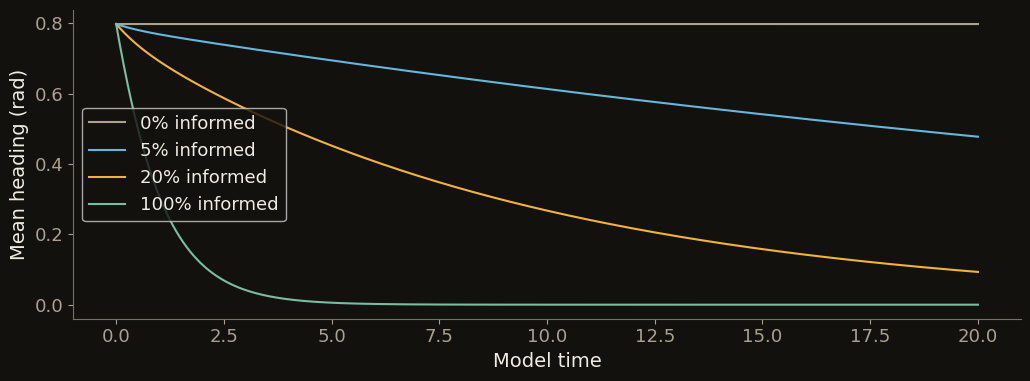

In [12]:
def informed_heading_step(heading,fraction=0.1,preference=1.,alignment=1.,dt=0.01):
    heading=np.asarray(heading,float)
    c,s=np.cos(heading).mean(),np.sin(heading).mean()
    informed=np.arange(len(heading))<round(fraction*len(heading))
    rate=alignment*(s*np.cos(heading)-c*np.sin(heading))-informed*preference*np.sin(heading)
    return heading+dt*rate

heading_start=0.8+0.35*np.sin(np.arange(40)*2.4)
fig,ax=plt.subplots()
for frac,color in zip([0.,.05,.2,1.],['#aaa18e','#67b7dc','#f2b33d','#79be9e']):
    h=heading_start.copy();means=[]
    for j in range(2001):
        means.append(np.arctan2(np.sin(h).mean(),np.cos(h).mean()))
        h=informed_heading_step(h,frac)
    ax.plot(np.arange(2001)*.01,means,color=color,label=f'{100*frac:g}% informed')
ax.set(xlabel='Model time',ylabel='Mean heading (rad)');ax.legend();plt.tight_layout();plt.show()


## Speed differences across a cohesive group

The golden-shiner experiment shows speed modulation by local light and strong social steering ([Berdahl et al., 2013](https://doi.org/10.1126/science.1225883)). This two-point example isolates one kinematic consequence. It is not a rigid-body model of a real school or a refit of the experiment.

$$\dot\vartheta=(v_{\rm right}-v_{\rm left})/d\simeq-\partial_\perp v.$$

Both ends sample the same light field. Turning the speed response off leaves the initial direction unchanged.

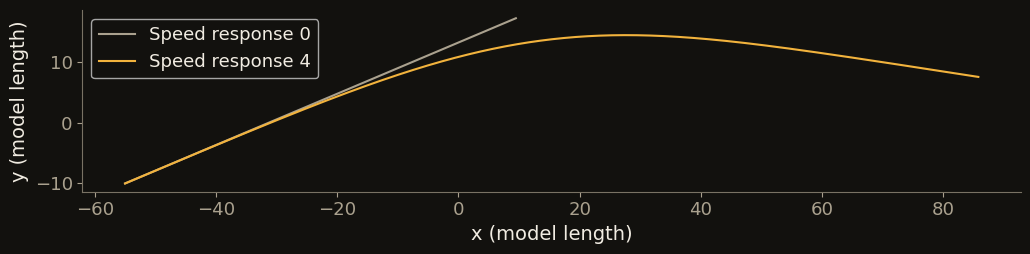

In [13]:
def light_field(x,y,time):
    cx,cy=15*np.sin(time/35),10*np.cos(time/40)
    return 1-0.9*np.exp(-((np.asarray(x)-cx)**2+(np.asarray(y)-cy)**2)/(2*22**2))

def sensing_step(state,time,dt=.02,separation=12.,gain=4.):
    x,y,heading=state
    nx,ny=-np.sin(heading),np.cos(heading)
    vl=2+gain*light_field(x+separation*nx/2,y+separation*ny/2,time)
    vr=2+gain*light_field(x-separation*nx/2,y-separation*ny/2,time)
    speed=(vl+vr)/2
    return np.array([x+dt*speed*np.cos(heading),y+dt*speed*np.sin(heading),heading+dt*(vr-vl)/separation])

fig,ax=plt.subplots()
for gain,color in [(0.,COLORS['muted']),(4.,COLORS['amber'])]:
    state=np.array([-55.,-10.,.4]);path=[]
    for j in range(1751):
        path.append(state.copy());state=sensing_step(state,j*.02,gain=gain)
    path=np.asarray(path);ax.plot(path[:,0],path[:,1],color=color,label=f'Speed response {gain:g}')
ax.set(xlabel='x (model length)',ylabel='y (model length)',aspect='equal');ax.legend();plt.tight_layout();plt.show()


## Directional order and spontaneous reversals

A symmetric model for signed marching order is

$$\dot m=a_{\rm march}m-b_{\rm march}m^3+\sqrt{2D_m}\,\eta(t),\qquad U(m)=-a_{\rm march}m^2/2+b_{\rm march}m^4/4.$$

The illustration uses reflecting boundaries at $m=\pm1$ and $p(m)\propto e^{-U(m)/D_m}$. These coefficients are not fitted locust measurements. The two-well distribution explains why the signed time average can vanish even when a group is ordered.

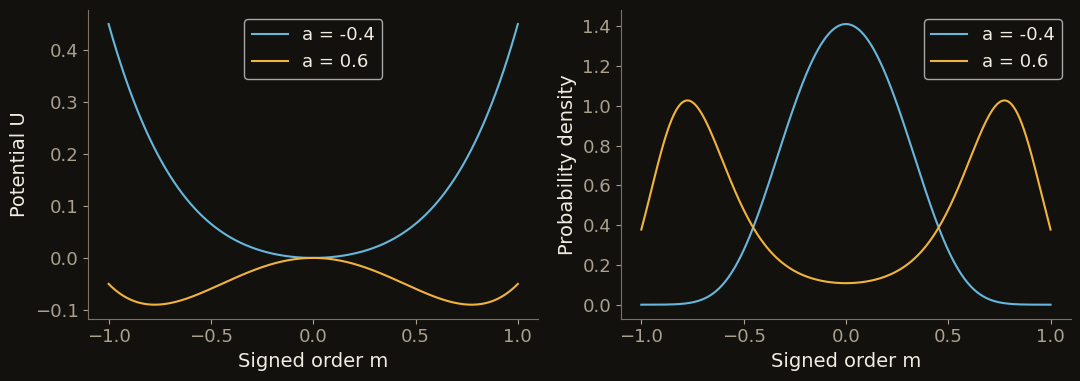

In [14]:
def marching_landscape(a=0.6,b=1.,noise=.04):
    m=np.linspace(-1,1,401);potential=-a*m*m/2+b*m**4/4
    weights=np.exp(-(potential-potential.min())/noise)
    density=weights/(weights.sum()*(m[1]-m[0]))
    return m,potential,density

fig,ax=plt.subplots(1,2,figsize=(11,4))
for a,color in [(-.4,COLORS['blue']),(.6,COLORS['amber'])]:
    m,u,density=marching_landscape(a)
    ax[0].plot(m,u,color=color,label=f'a = {a:g}')
    ax[1].plot(m,density,color=color,label=f'a = {a:g}')
ax[0].set(xlabel='Signed order m',ylabel='Potential U');ax[1].set(xlabel='Signed order m',ylabel='Probability density');ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()


## A directional-choice landscape

The two-target virtual-reality comparison in [Sayin et al. (2025), Figure 5](https://doi.org/10.1126/science.adq7832) motivates a distinction between averaging directions and choosing one. This illustrative potential has two target bearings $\pm\beta_0$:

$$U(\vartheta)=-\sum_{\beta=\pm\beta_0}e^{\kappa_{\rm choice}\cos(\vartheta-\beta)}.$$

The midpoint curvature is $2\kappa e^{\kappa\cos\beta_0}(\cos\beta_0-\kappa\sin^2\beta_0)$. Its sign change permits two preferred directions. This is not the paper’s fitted neural model.

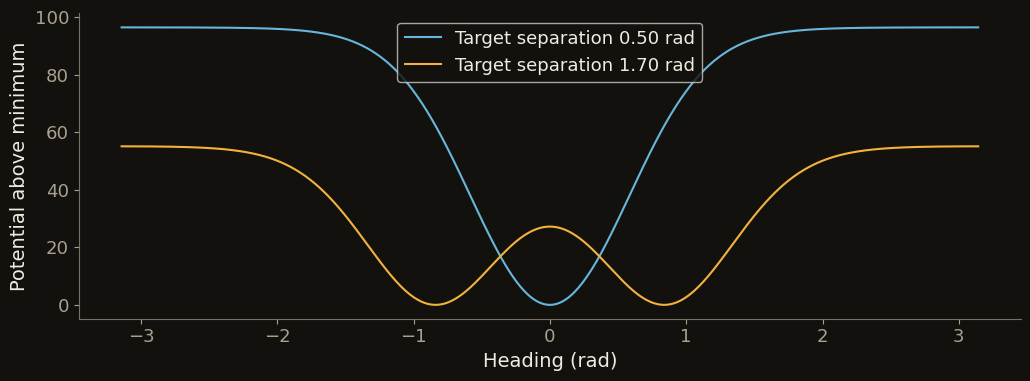

In [15]:
def choice_potential(angle,beta=.7,sharpness=4.):
    angle=np.asarray(angle)
    return -np.exp(sharpness*np.cos(angle-beta))-np.exp(sharpness*np.cos(angle+beta))

def choice_curvature(beta,sharpness):
    return 2*sharpness*np.exp(sharpness*np.cos(beta))*(np.cos(beta)-sharpness*np.sin(beta)**2)

angles=np.linspace(-np.pi,np.pi,721)
fig,ax=plt.subplots()
for beta,color in [(.25,COLORS['blue']),(.85,COLORS['amber'])]:
    u=choice_potential(angles,beta);ax.plot(angles,u-u.min(),color=color,label=f'Target separation {2*beta:.2f} rad')
ax.set(xlabel='Heading (rad)',ylabel='Potential above minimum');ax.legend();plt.tight_layout();plt.show()
eps=1e-4
assert np.isclose((choice_potential(eps)-2*choice_potential(0.)+choice_potential(-eps))/eps**2,choice_curvature(.7,4.),rtol=1e-6)


## Alignment modes on a fixed network

For a symmetric fixed network, $\dot{\delta\boldsymbol\vartheta}=-J_{\rm align}\boldsymbol\Lambda_{\rm align}\delta\boldsymbol\vartheta+\boldsymbol\xi$. Each positive mode relaxes with $\tau_\alpha=(J_{\rm align}\lambda_\alpha)^{-1}$. A nearest-neighbor ring makes the eigenvalues explicit:

$$\lambda_k=4\sin^2(\pi k/N).$$

This planar example explains the calculation used in dynamical inference. The source starling estimates are the published results in [Mora et al. (2016)](https://doi.org/10.1038/nphys3846), not fits to these generated examples.

## Separate the neighbors’ headings from the bird’s own heading


- $\delta\vartheta_i$: bird $i$’s heading deviation from a common reference direction.
- $w_{ij}$: influence of bird $j$ on bird $i$. Sum over all birds; $w_{ii}=0$.
$$
\dot{\delta\vartheta}_i=J_{\rm align}\sum_j w_{ij}(\delta\vartheta_j-\delta\vartheta_i)+\xi_i
$$

$$
=J_{\rm align}\left[\underbrace{\sum_jw_{ij}\delta\vartheta_j}_{\text{neighbors}}-\underbrace{\left(\sum_jw_{ij}\right)\delta\vartheta_i}_{\text{bird }i}\right]+\xi_i
$$

- The same alignment rule, with the two contributions written separately.

## The Laplacian collects these coefficients into a matrix


- Three birds in a chain: $1\leftrightarrow2\leftrightarrow3$, with unit weight on each link.
$$
\begin{pmatrix}\dot{\delta\vartheta}_1\\\dot{\delta\vartheta}_2\\\dot{\delta\vartheta}_3\end{pmatrix}=-J_{\rm align}\underbrace{\begin{pmatrix}1&-1&0\\-1&2&-1\\0&-1&1\end{pmatrix}}_{\boldsymbol\Lambda_{\rm align}}\begin{pmatrix}\delta\vartheta_1\\\delta\vartheta_2\\\delta\vartheta_3\end{pmatrix}+\boldsymbol\xi
$$

- Diagonal: total weight of a bird’s neighbors. Off-diagonal: negative interaction weight.
- Row 2 gives $\dot{\delta\vartheta}_2=J_{\rm align}(\delta\vartheta_1-2\delta\vartheta_2+\delta\vartheta_3)+\xi_2$.
$$
\dot{\delta\boldsymbol\vartheta}=-J_{\rm align}\boldsymbol\Lambda_{\rm align}\delta\boldsymbol\vartheta+\boldsymbol\xi
$$


## A mode is a heading pattern that keeps its shape as it relaxes


- Use fixed, symmetric interaction weights. An eigenvector specifies one heading deviation per bird.
$$
\boldsymbol\Lambda_{\rm align}\mathbf u_\alpha=\lambda_\alpha\mathbf u_\alpha
$$
| Three-bird pattern | Eigenvalue | Heading differences |
| --- | --- | --- |
| $(1,1,1)$ | $0$ | All birds turn together |
| $(1,0,-1)$ | $1$ | Heading changes across the chain |
| $(1,-2,1)$ | $3$ | Middle bird opposes both neighbors |


- These three patterns can be combined to describe any small heading perturbation of the three birds.
- Uniform rotation creates no disagreement, so alignment does not restore it.

## Each mode reduces the coupled equations to one decay equation


- Follow one mode: $\delta\boldsymbol\vartheta(t)=c_\alpha(t)\mathbf u_\alpha$. Set noise to zero to calculate its relaxation.
$$
\dot c_\alpha\mathbf u_\alpha=-J_{\rm align}c_\alpha\boldsymbol\Lambda_{\rm align}\mathbf u_\alpha=-J_{\rm align}\lambda_\alpha c_\alpha\mathbf u_\alpha
$$

$$
\dot c_\alpha=-J_{\rm align}\lambda_\alpha c_\alpha\quad\Longrightarrow\quad c_\alpha(t)=c_\alpha(0)e^{-J_{\rm align}\lambda_\alpha t}
$$

$$
\tau_\alpha=\frac{1}{J_{\rm align}\lambda_\alpha}\qquad(\lambda_\alpha>0)
$$

- The middle-against-ends pattern decays three times faster than the gradual pattern in the three-bird example.

## Local alignment can be fast while a broad heading pattern relaxes slowly


- Example: birds interact with their two neighbors on a ring.
- A smooth heading pattern produces small differences between neighbors and relaxes slowly.
- An alternating pattern produces large differences and relaxes quickly.
$$
\text{Decay rate}=J_{\rm align}\lambda_\alpha
$$

- Local relaxation and relaxation across the whole flock are different time scales.

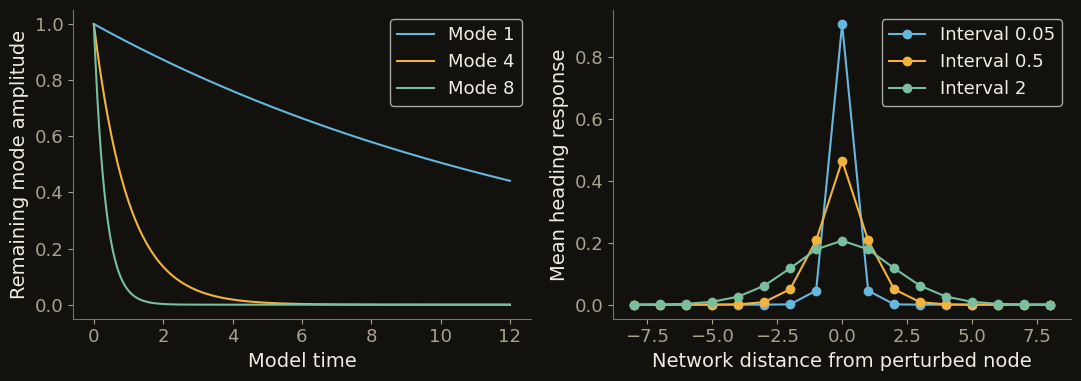

In [16]:
from scipy.linalg import expm

def ring_laplacian(size=24):
    identity=np.eye(size)
    return 2*identity-np.roll(identity,1,axis=0)-np.roll(identity,-1,axis=0)

def ring_kernel(size=24,rate=1.,interval=.5):
    modes=np.arange(size);lam=4*np.sin(np.pi*modes/size)**2
    return np.array([np.mean(np.exp(-rate*lam*interval)*np.cos(2*np.pi*modes*j/size)) for j in range(size)])

lap=ring_laplacian();eigenvalues,eigenvectors=np.linalg.eigh(lap)
assert np.allclose(lap.sum(axis=1),0)
assert np.allclose(ring_kernel(),expm(-.5*lap)[:,0],atol=1e-14)
fig,ax=plt.subplots(1,2,figsize=(11,4))
times=np.linspace(0,12,241)
for mode,color in [(1,COLORS['blue']),(4,COLORS['amber']),(8,COLORS['green'])]:
    lam=4*np.sin(np.pi*mode/24)**2
    ax[0].plot(times,np.exp(-lam*times),color=color,label=f'Mode {mode}')
for interval,color in [(.05,COLORS['blue']),(.5,COLORS['amber']),(2.,COLORS['green'])]:
    distance=np.arange(-8,9);kernel=ring_kernel(interval=interval)
    ax[1].plot(distance,kernel[distance%24],'o-',color=color,label=f'Interval {interval:g}')
ax[0].set(xlabel='Model time',ylabel='Remaining mode amplitude');ax[1].set(xlabel='Network distance from perturbed node',ylabel='Mean heading response');ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()


## An exact Gaussian transition likelihood

Remove the uniform-rotation mode. With angular noise covariance $2D_{\rm ang}\mathbf I\delta(t-t')$, the positive modes have independent finite-time transitions:

$$y_\alpha(t+\Delta t)\sim\mathcal N(e^{-J\lambda_\alpha\Delta t}y_\alpha(t),\;D_{\rm ang}[1-e^{-2J\lambda_\alpha\Delta t}]/[J\lambda_\alpha]).$$

The likelihood includes the accumulated noise covariance. The example below generates exact transitions, then estimates the alignment rate with noise strength held fixed. It is a numerical check on known synthetic data.

## Fit the change between frames, using the decay we just derived


- The camera records headings at times $t$ and $t+\Delta t$. Project them onto a mode to measure $c_\alpha(t)$ and $c_\alpha(t+\Delta t)$.
$$
\underbrace{\mathbb E[c_\alpha(t+\Delta t)\mid c_\alpha(t)]}_{\text{predicted amplitude at the next frame}}=c_\alpha(t)e^{-\Delta t/\tau_\alpha},\qquad \tau_\alpha^{-1}=J_{\rm align}\lambda_\alpha
$$

- A short-time (Euler) fit replaces the exponential by a straight line:
$$
e^{-\Delta t/\tau_\alpha}\simeq1-\frac{\Delta t}{\tau_\alpha}\qquad\text{only when }\Delta t\ll\tau_\alpha
$$

- If a mode relaxes substantially between frames, that approximation changes the inferred interaction.

## Noise gives a spread around the predicted heading change


- For a positive mode, the next amplitude is the predicted mean plus a random contribution:
$$
c_\alpha(t+\Delta t)=c_\alpha(t)e^{-\Delta t/\tau_\alpha}+\text{Gaussian noise}
$$

$$
\underbrace{\operatorname{Var}[\text{noise}]}_{\text{spread between repeated observations}}=D_{\rm ang}\tau_\alpha\left(1-e^{-2\Delta t/\tau_\alpha}\right)
$$

- $D_{\rm ang}$ is angular noise strength. At short intervals, the variance is $2D_{\rm ang}\Delta t$; at long intervals, it approaches $D_{\rm ang}\tau_\alpha$.
- Fit the interaction weights, alignment rate, and noise strength by making the observed frame-to-frame changes most probable.
- Both the predicted change and its expected scatter enter the fit.

## Skipping frames should not change how many neighbors a bird follows


- $n_c$ sets the range in neighbor rank: $w_{ij}\propto e^{-k_{ij}/n_c}$, where $k_{ij}=1$ is the nearest bird.
- **A:** simulations recover known ranges. **B:** the same simulation is sampled less often. **C:** the same test on starling recordings.
- **Red, exact:** inferred range stays stable. **Green, Euler:** inferred range grows as frames are skipped.

## Snapshots and dynamics give similar interaction ranges


- Noise excites each mode; alignment damps it. The steady variance is
$$
\langle c_\alpha^2\rangle=D_{\rm ang}\tau_\alpha=\frac{D_{\rm ang}}{J_{\rm align}\lambda_\alpha}
$$

- **Horizontal:** fit simultaneous heading fluctuations. **Vertical:** fit changes between frames.
- Each point: one flock. Dashed line: equality. Dynamical estimates are generally higher.
- Headings relax before neighbors change, allowing snapshot inference.

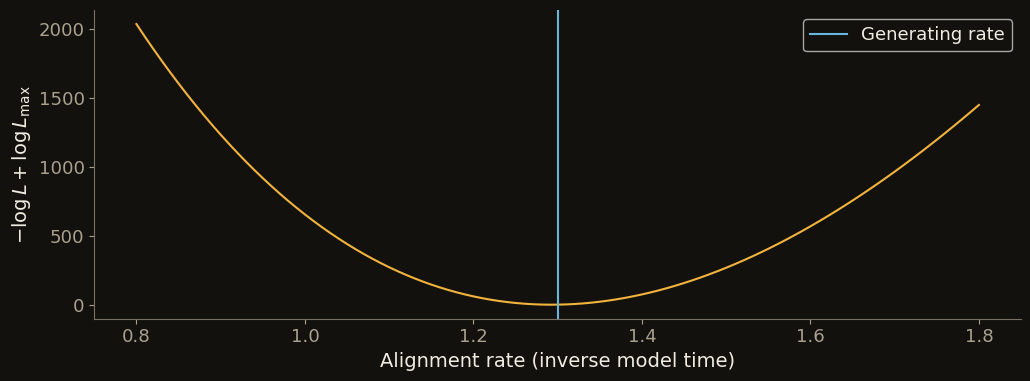

Generating rate 1.300; inferred rate 1.293


In [17]:
from scipy.optimize import minimize_scalar

def modal_transition(eigenvalues,rate,noise,interval):
    eigenvalues=np.asarray(eigenvalues,float)
    decay=np.exp(-rate*eigenvalues*interval)
    variance=noise*(-np.expm1(-2*rate*eigenvalues*interval))/(rate*eigenvalues)
    return decay,variance

positive=eigenvalues[1:];true_rate=1.3;noise_strength=.025;sample_interval=.7
local_rng=np.random.default_rng(151516)
decay,variance=modal_transition(positive,true_rate,noise_strength,sample_interval)
y=local_rng.normal(size=(2501,len(positive)))*np.sqrt(noise_strength/(true_rate*positive))
for t in range(2500):y[t+1]=decay*y[t]+local_rng.normal(size=len(positive))*np.sqrt(variance)
def transition_nll(rate):
    decay,variance=modal_transition(positive,rate,noise_strength,sample_interval)
    residual=y[1:]-decay*y[:-1]
    return .5*np.sum(np.log(2*np.pi*variance)+residual**2/variance)
fit=minimize_scalar(transition_nll,bounds=(.2,3.),method='bounded')
assert abs(fit.x-true_rate)<.08
fig,ax=plt.subplots();rates=np.linspace(.8,1.8,101);loss=np.array([transition_nll(v) for v in rates]);ax.plot(rates,loss-loss.min(),color=COLORS['amber']);ax.axvline(true_rate,color=COLORS['blue'],label='Generating rate');ax.set(xlabel='Alignment rate (inverse model time)',ylabel=r'$-\log L+\log L_{\max}$');ax.legend();plt.tight_layout();plt.show()
print(f'Generating rate {true_rate:.3f}; inferred rate {fit.x:.3f}')


## Local heading relaxation

HTML slide 52. With neighboring headings fixed, a small angular deviation relaxes as

$$
\frac{d\delta\vartheta}{dt}=-\frac{\delta\vartheta}{\tau_{\rm relax}},\qquad
\delta\vartheta(t)=\delta\vartheta(0)e^{-t/\tau_{\rm relax}}.
$$

The exact update below describes one deterministic local mode. It is not a fit to the birds or a complete stochastic flock model.

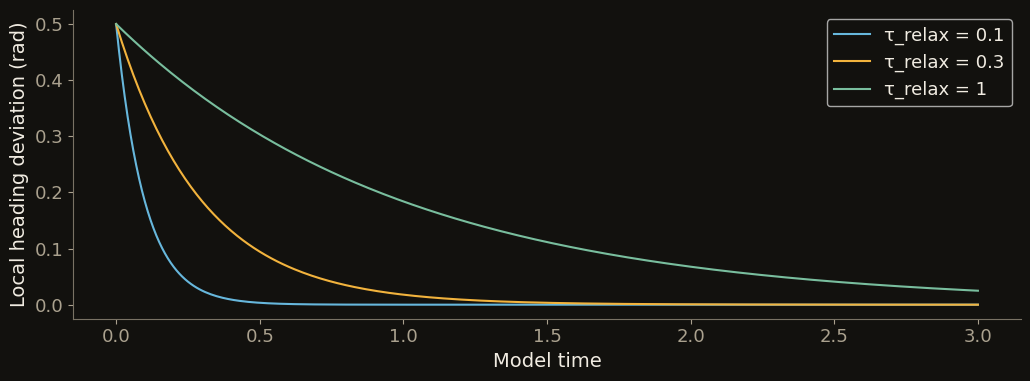

In [18]:
def relaxation_step(angle,target,dt,tau_relax):
    if tau_relax <= 0 or dt < 0:
        raise ValueError('Relaxation time must be positive and dt nonnegative.')
    return target+(angle-target)*np.exp(-dt/tau_relax)

local_time=np.linspace(0,3,301)
fig,ax=plt.subplots()
for tau,color in zip([.1,.3,1.],[COLORS['blue'],COLORS['amber'],COLORS['green']]):
    ax.plot(local_time,.5*np.exp(-local_time/tau),color=color,label=f'τ_relax = {tau:g}')
ax.set(xlabel='Model time',ylabel='Local heading deviation (rad)');ax.legend()
plt.tight_layout();plt.show()
assert np.isclose(relaxation_step(.5,0,.2,.2),.5/np.e)
assert np.isclose(relaxation_step(relaxation_step(.5,-.1,.1,.2),-.1,.2,.2),relaxation_step(.5,-.1,.3,.2))
packet['local_alignment']={'initial_angle':.5,'tau_relax':.2,'tau_network':3.,'dt':.01,
 'interpretation':'Deterministic small-angle illustration; no fitted biological parameters or stochastic inference.'}


### Heading relaxation and neighbor exchange

HTML slide 53. An imposed local mean changes every $\tau_{\rm network}$; the focal heading relaxes toward it with time $\tau_{\rm relax}$. This isolates the competition between local adjustment and a changing target. Model times and parameters are illustrative.

$$
\frac{d\vartheta}{dt}=-\frac{\vartheta-\vartheta_{\rm nb}(t)}{\tau_{\rm relax}}.
$$

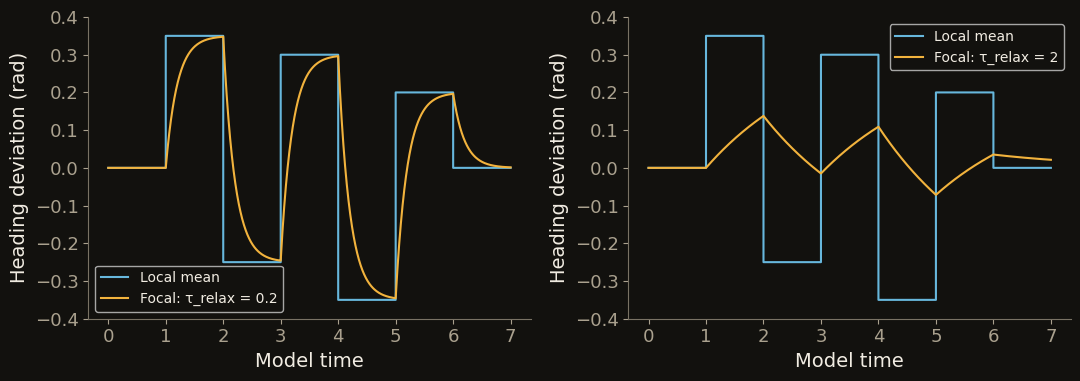

Tracking RMSE, fast / slow relaxation: [0.152 0.244]


In [19]:
LOCAL_TARGETS=np.array([0.,.35,-.25,.3,-.35,.2,0.])

def changing_neighbors(tau_relax=.2,tau_network=3.,dt=.01):
    if tau_network <= 0 or dt <= 0:
        raise ValueError('Exchange interval and time step must be positive.')
    steps=int(round(7*tau_network/dt))
    time=np.arange(steps+1)*dt
    target=LOCAL_TARGETS[np.minimum(np.floor(time/tau_network+1e-9).astype(int),6)]
    angle=np.zeros(len(time))
    for k in range(steps):
        angle[k+1]=relaxation_step(angle[k],target[k],dt,tau_relax)
    return dict(time=time,angle=angle,target=target)

fig,axes=plt.subplots(1,2,figsize=(11,4))
tracking_errors=[]
for ax,tau in zip(axes,[.2,2.]):
    trajectory=changing_neighbors(tau_relax=tau,tau_network=1.)
    ax.step(trajectory['time'],trajectory['target'],where='post',color=COLORS['blue'],label='Local mean')
    ax.plot(trajectory['time'],trajectory['angle'],color=COLORS['amber'],label=f'Focal: τ_relax = {tau:g}')
    ax.set(xlabel='Model time',ylabel='Heading deviation (rad)',ylim=(-.4,.4));ax.legend(fontsize=10)
    tracking_errors.append(float(np.sqrt(np.mean((trajectory['angle']-trajectory['target'])**2))))
plt.tight_layout();plt.show()
assert tracking_errors[0]<tracking_errors[1]
print('Tracking RMSE, fast / slow relaxation:',np.round(tracking_errors,3))
packet['local_alignment']['targets']=LOCAL_TARGETS


### Measured separation of timescales in starlings

HTML slide 54. Mora et al. (2016), [paper](https://doi.org/10.1038/nphys3846), infer local relaxation from heading dynamics and measure network memory from changing weighted neighbor links.

![Alignment and neighbor-exchange time distributions](../media/flocking/mora-2016-timescales.png)

The blue and red distributions describe published event estimates, not a new fit to trajectory data. In the source model, $\tau_{\rm relax}\sim(J_{\rm align}n_c)^{-1}$; $J_{\rm align}$ has units of inverse time and $n_c$ sets an exponentially weighted neighbor-rank range. The source figure writes this rate as $J$.

### Snapshot and dynamical inference

HTML slide 55. The inferred alignment-range parameter $n_c$ agrees between a fit to simultaneous headings and a fit to their changes in time.

![Snapshot versus dynamical alignment-range estimates](../media/flocking/mora-2016-inference.png)

The separation $\tau_{\rm relax}\ll\tau_{\rm network}$ supports a local quasi-equilibrium approximation. It does not make the whole flock thermally equilibrated or determine a flock-wide propagation time. The intervals are standard errors over time frames. The paper's full inference derivation is optional.

## Diffusion and turning waves

HTML slides 56–59.

$$
\partial_t\vartheta=D_\vartheta\partial_x^2\vartheta,
$$
$$
\partial_t^2\vartheta+\gamma_{\rm turn}\partial_t\vartheta=c_s^2\partial_x^2\vartheta.
$$

Both models start from the same small heading disturbance on a periodic domain.

## Our model predicts diffusion, but starling turns travel as waves

- The previous alignment model, applied to a chain of neighbors, predicts **diffusive spreading**:
$$
\partial_t\delta\vartheta=D_\vartheta\partial_x^2\delta\vartheta
$$

$$
\text{distance reached}\propto\sqrt{t}
$$

- **Starling measurements:** the distance reached grows approximately linearly with time during the turn’s initial spread.
- **A nearly constant propagation speed—a wave.**

## A bird’s turning rate persists while its neighbors respond

- In the previous model, heading differences set the turning rate immediately.
- In this model, neighbors change a bird’s turning rate; damping reduces it.
$$
\underbrace{\partial_t^2\delta\vartheta}_{\text{angular acceleration}}=\underbrace{c_s^2\partial_x^2\delta\vartheta}_{\text{response to neighbors}}-\underbrace{\gamma_{\rm turn}\partial_t\delta\vartheta}_{\text{damping of turning}}
$$
| Condition | Equation | Meaning |
| --- | --- | --- |
| Without neighbor input | $\partial_t\delta\vartheta\propto e^{-\gamma_{\rm turn}t}$ | A bird’s turning rate dies away gradually. |
| Without damping | $\partial_t^2\delta\vartheta=c_s^2\partial_x^2\delta\vartheta$ | A heading disturbance travels as a wave. | 

- $c_s$: undamped signal speed. $\gamma_{\rm turn}$: damping rate. This persistence is **behavioral inertia**.

## The wave solution gives both a speed and a decay time

- For a sinusoidal heading pattern, $\delta\vartheta\propto e^{i(kx-\omega t)}$, with $k=2\pi/\text{wavelength}$:
$$
-\omega^2-i\gamma_{\rm turn}\omega=-c_s^2k^2\quad\Longrightarrow\quad\omega_\pm=-\frac{i\gamma_{\rm turn}}2\pm\sqrt{c_s^2k^2-\frac{\gamma_{\rm turn}^2}{4}}
$$

- When damping is weak, $\gamma_{\rm turn}\ll2c_s|k|$, the real heading pattern is approximately
$$
\delta\vartheta(x,t)\simeq\underbrace{A_0e^{-\gamma_{\rm turn}t/2}}_{\text{shrinking amplitude}}\qquad\underbrace{\cos[k(x\mp c_st)]}_{\text{pattern moving at }c_s}
$$

- **Propagation speed:** $c_s$. **Amplitude decay time:** $2/\gamma_{\rm turn}$.

## Persistent turning sends the disturbance outward

- **Same initial heading change:** diffusion broadens it; turning dynamics produces two traveling signals.
- Color shows heading deviation. Sloping bands show propagation; increasing damping weakens them.

## Damping would weaken the turn as it crosses the flock

- A wave can travel but still fade before it reaches the other side of the flock.
$$
\frac{A(L)}{A_0}=e^{-t_{\rm cross}/\tau_{\rm decay}}
$$
$t_{\rm cross}=L/c_s$: time to cross the flock.
$\tau_{\rm decay}=2/\gamma_{\rm turn}$: amplitude decay time.
- **Strong damping predicts weaker turns in birds reached later.**
- Peak turning accelerations test whether that weakening actually occurs.

## Starling turns cross the flock with little loss of strength

- **Red birds turn first, green birds next, blue birds last.** The curves show their radial accelerations.
- Later birds turn almost as strongly. The inset shows little decline in peak acceleration across the turning order.
- **The turn crosses the flock before it fades.** Together with the constant propagation speed, this is the behavior of a weakly damped wave.
- Local interactions can coordinate a whole-flock turn.

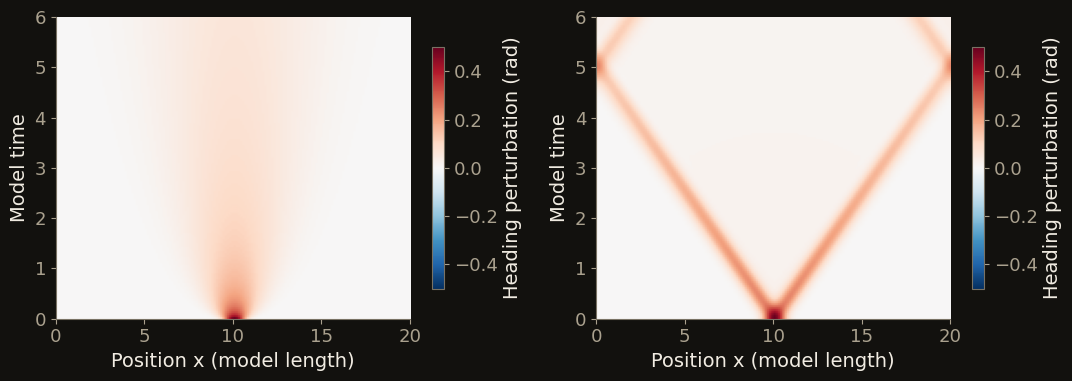

In [20]:
def propagation_step(angle,rate,dt,dx,model='wave',diffusivity=1.,c=2.,damping=.3):
    lap=(np.roll(angle,-1)-2*angle+np.roll(angle,1))/dx**2
    if model=='diffusion':
        return angle+dt*diffusivity*lap,np.zeros_like(rate)
    next_rate=(rate+dt*c*c*lap)/(1+damping*dt)
    return angle+dt*next_rate,next_rate

wave_x=np.arange(160)*.125
wave_initial=.5*np.exp(-((wave_x-10)/.6)**2)
wave_histories={}
for model in ['diffusion','wave']:
    angle=wave_initial.copy();rate=np.zeros_like(angle);frames=[]
    for k in range(1501):
        if k%10==0:frames.append(angle.copy())
        angle,rate=propagation_step(angle,rate,.004,.125,model=model)
    wave_histories[model]=np.array(frames)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for axis,model in zip(ax,['diffusion','wave']):
    a=axis.imshow(wave_histories[model],origin='lower',aspect='auto',extent=(0,20,0,6),vmin=-.5,vmax=.5,cmap='RdBu_r')
    axis.set(xlabel='Position x (model length)',ylabel='Model time');fig.colorbar(a,ax=axis,label='Heading perturbation (rad)',shrink=.8)
plt.tight_layout();plt.show()
packet['propagation']={'x':wave_x,'initial':wave_initial,'dt':.004,'dx':.125,'histories':wave_histories,'frame_dt':.04}

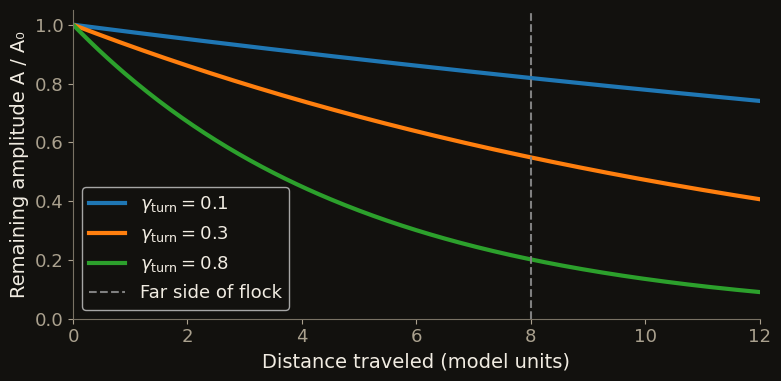

In [21]:
def turn_reach(distance, speed, damping):
    """Weak-damping traveling-wave amplitude envelope; distances in model units."""
    return np.exp(-damping*np.asarray(distance)/(2*speed))

assert np.allclose(turn_reach([0, 4, 8], 2, .5), [1, np.exp(-.5), np.exp(-1)])
assert np.allclose(turn_reach([0, 12], 2, 0), [1, 1])
distance = np.linspace(0, 12, 241)
fig, ax = plt.subplots(figsize=(8, 4))
for damping in [.1, .3, .8]:
    ax.plot(distance, turn_reach(distance, 2, damping), lw=3,
            label=fr"$\gamma_{{\rm turn}}={damping}$")
ax.axvline(8, color="0.5", ls="--", label="Far side of flock")
ax.set(xlabel="Distance traveled (model units)", ylabel="Remaining amplitude A / A₀",
       xlim=(0, 12), ylim=(0, 1.05))
ax.legend()
plt.tight_layout()
plt.show()


### Optional: the wave spectrum

Angular wavenumber $k=2\pi/\lambda$ and angular frequency $\omega$ give a ridge near $|\omega|=c_s|k|$ for the traveling wave.

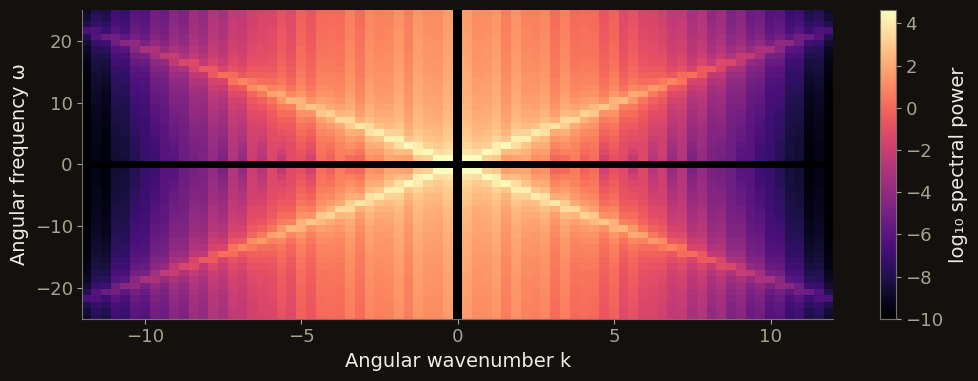

In [22]:
field=wave_histories['wave'];spectrum=np.abs(np.fft.fftshift(np.fft.fft2(field-field.mean(axis=0))))**2
k=2*np.pi*np.fft.fftshift(np.fft.fftfreq(field.shape[1],d=.125))
w=2*np.pi*np.fft.fftshift(np.fft.fftfreq(field.shape[0],d=.04))
fig,ax=plt.subplots();im=ax.imshow(np.log10(spectrum+1e-10),origin='lower',aspect='auto',extent=(k[0],k[-1],w[0],w[-1]),cmap='magma');ax.set(xlabel='Angular wavenumber k',ylabel='Angular frequency ω',xlim=(-12,12),ylim=(-25,25));fig.colorbar(im,ax=ax,label='log₁₀ spectral power');plt.tight_layout();plt.show()

## Propagation and damping of heading modes

For $e^{i(kx-\omega t)}$, diffusion gives $\omega=-iD_\vartheta k^2$. The damped turning-wave equation gives

$$\omega_\pm=-i\gamma_{\rm turn}/2\pm\sqrt{c_s^2k^2-\gamma_{\rm turn}^2/4}.$$

A negative imaginary part is decay with this time convention. Both branches become purely relaxational below the propagation threshold.

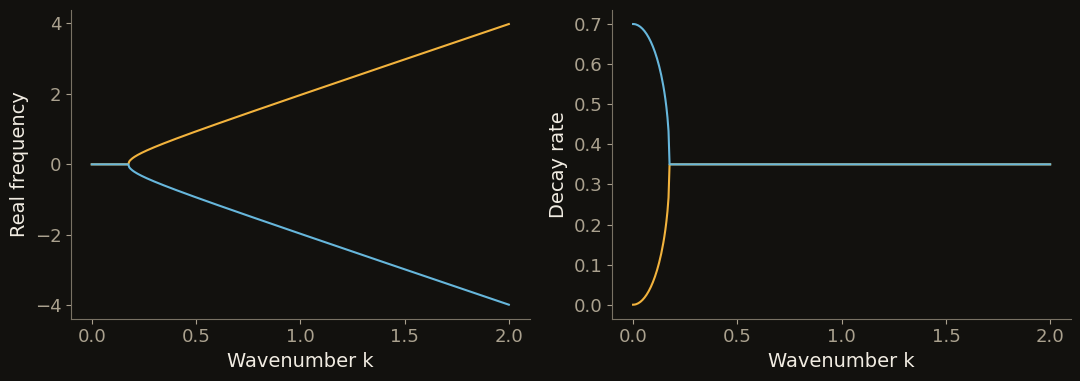

In [23]:
def wave_dispersion(k,speed=2.,damping=.7):
    root=np.sqrt((speed*np.asarray(k))**2-damping**2/4+0j)
    return -.5j*damping+root,-.5j*damping-root

k=np.linspace(0,2,401);plus,minus=wave_dispersion(k)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for branch,color in [(plus,COLORS['amber']),(minus,COLORS['blue'])]:
    ax[0].plot(k,branch.real,color=color);ax[1].plot(k,-branch.imag,color=color)
ax[0].set(xlabel='Wavenumber k',ylabel='Real frequency');ax[1].set(xlabel='Wavenumber k',ylabel='Decay rate');plt.tight_layout();plt.show()
assert np.all(plus.imag<=1e-12) and np.all(minus.imag<=1e-12)


## Fly counts reveal crowding

HTML slides 59–64.

The measured count $N_b(t)$ gives a distribution $p_b(n)$ in each spatial bin. Compare that distribution with independent flies at the same mean, then fit a shared crowding cost and a location-dependent preference.

Méndez-Valderrama et al. (2018), [paper](https://doi.org/10.1038/s41467-018-05750-z), [data](https://osf.io/7ubz2/). The deposited rectangle variable includes `96flies` in its name, but observed frame totals are 56–66; the filename is not a population measurement.

In [24]:
fly_dir=DATA/'flies/dfft-2018'
rect=loadmat(fly_dir/'figure-03-rectangle-high-occupancies.mat')['occ_rectangle_96flies'].astype(int)
c_low=loadmat(fly_dir/'figure-03-c-shape-low-occupancies.mat')['occ_C_2flies'].astype(int)
c_high=loadmat(fly_dir/'figure-03-c-shape-high-occupancies.mat')['occ_C_189flies'].astype(int)
square_low=loadmat(fly_dir/'figure-03-square-low-occupancies.mat')['occ_square_1fly'].astype(int)
square_high=loadmat(fly_dir/'figure-03-square-high-occupancies.mat')['occ_square_125flies'].astype(int)
areas=json.loads((fly_dir/'physical-bin-areas.json').read_text())['bin_area_cm2']
assert c_low.shape[1]==c_high.shape[1]==37
assert np.all(c_low.sum(axis=1)==2) and np.all(c_high.sum(axis=1)==189)
print({'rectangle_mean_observed_total':round(float(rect.sum(axis=1).mean()),2),'C_sparse_total':2,'C_crowded_total':189,'bin_areas_cm2':areas})

{'rectangle_mean_observed_total': 63.47, 'C_sparse_total': 2, 'C_crowded_total': 189, 'bin_areas_cm2': {'rectangle': 0.1493, 'square': 0.1389, 'stairs': 0.6065, 'c_shape': 0.3514}}


### Optional: exact fixed-population count statistics

The lecture uses single-bin probabilities. This calculation keeps the total population fixed exactly and enumerates all configurations of six animals in three bins. Their multiplicity is $N!/\prod_bN_b!$.

$$\mathcal P(\{N_b\}\mid N)\propto\mathbf1_{\sum_bN_b=N}\prod_b\frac{e^{-f_{N_b}-V_bN_b}}{N_b!}.$$

The fixed-total constraint couples the bins. The numerical check verifies $-\partial_{V_c}\langle N_b\rangle=\operatorname{Cov}(N_b,N_c)$. This response identity is optional detail, outside the projected sequence.

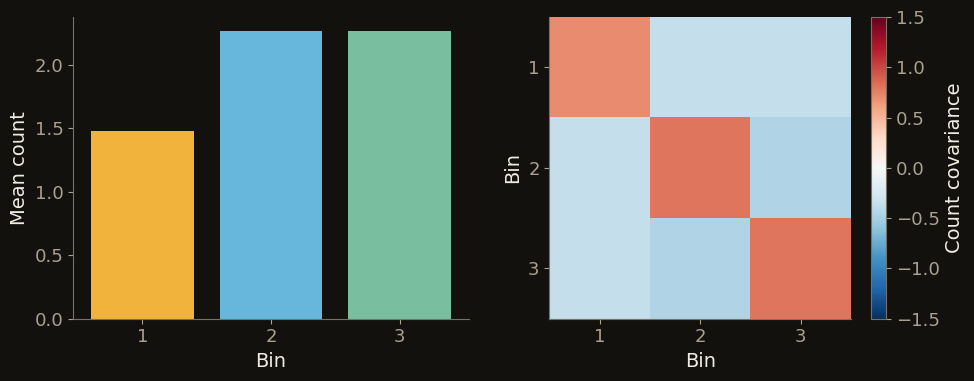

In [25]:
def canonical_counts(total=6,potential=(0.,0.,0.),crowding=.4):
    states=np.array([[a,b,total-a-b] for a in range(total+1) for b in range(total-a+1)],float)
    logweight=-np.sum(.5*crowding*states*(states-1)+states*np.asarray(potential)+gammaln(states+1),axis=1)
    probability=np.exp(logweight-logsumexp(logweight))
    mean=probability@states
    covariance=(states-mean).T@(probability[:,None]*(states-mean))
    return mean,covariance,probability,states

means,covariance,probability,states=canonical_counts(potential=(.7,0.,0.))
assert np.allclose(states.sum(axis=1),6) and np.isclose(means.sum(),6)
assert np.allclose(covariance.sum(axis=1),0,atol=1e-12)
eps=1e-4
response=-(canonical_counts(potential=(.7+eps,0,0))[0]-canonical_counts(potential=(.7-eps,0,0))[0])/(2*eps)
assert np.allclose(response,covariance[:,0],rtol=1e-7,atol=1e-9)
fig,ax=plt.subplots(1,2,figsize=(10,4));ax[0].bar(range(1,4),means,color=[COLORS['amber'],COLORS['blue'],COLORS['green']]);ax[0].set(xlabel='Bin',ylabel='Mean count',xticks=range(1,4));im=ax[1].imshow(covariance,cmap='RdBu_r',vmin=-1.5,vmax=1.5);ax[1].set(xlabel='Bin',ylabel='Bin',xticks=range(3),yticks=range(3),xticklabels=range(1,4),yticklabels=range(1,4));fig.colorbar(im,ax=ax[1],label='Count covariance');plt.tight_layout();plt.show()


### One count law separates preference from crowding

HTML slide 63.

$$p_b(n)=\frac{e^{-f_n-(V_b-\mu_{\rm occ})n}}{\mathcal Z_b\,n!}.$$

$V_b$ is an effective environmental potential: lower values make a location more favorable. It is dimensionless and inferred from occupancy, rather than a mechanical potential energy. $f_n$ is the crowding cost for $n$ flies, shared among all bins. $\mu_{\rm occ}$ sets the mean total, while $\mathcal Z_b$ normalizes each bin. Setting $f_n=0$ recovers a Poisson law. The single-bin model fixes the total on average.

In [26]:
def count_probabilities(f,V,mu=0.):
    f=np.asarray(f,float);V=np.atleast_1d(V).astype(float);n=np.arange(len(f))
    log_weight=-f[None,:]-(V[:,None]-mu)*n-gammaln(n+1)
    return np.exp(log_weight-logsumexp(log_weight,axis=1,keepdims=True))

def count_mean(f,V,mu=0.):
    return count_probabilities(f,V,mu)@np.arange(len(f))

assert np.allclose(count_probabilities(np.zeros(50),[-1,0,1]).sum(axis=1),1)
assert np.allclose(count_mean(np.zeros(50),[-1,0,1]),np.exp(-np.array([-1,0,1])))

### Independent flies provide the fluctuation baseline

HTML slide 62 compares a measured histogram with a Poisson distribution of the same mean. For independent animals at exactly fixed total, the underlying count law is binomial:

$$N_b\sim\operatorname{Binomial}(N,q_b),\qquad \operatorname{Var}(N_b)=Nq_b(1-q_b).$$

The calculation below uses an illustrative fixed population of 65. Small $q_b$ gives the Poisson approximation, with variance approximately equal to the mean.

In [27]:
from scipy.stats import binom,poisson
N_reference=65
independent_n=np.arange(18)
q_reference=float(rect.mean(axis=0).max()/N_reference)
packet['independent_counts']={'N':N_reference,'q':q_reference,'n':independent_n,
 'binomial':binom.pmf(independent_n,N_reference,q_reference),'poisson':poisson.pmf(independent_n,N_reference*q_reference),
 'rectangle_variance':rect.var(axis=0,ddof=1)}

### Fit the crowding cost in the rectangle

HTML slides 63–64. All bins share $f_n$ and have separate $V_b$. Set $f_0=f_1=0$ to fix the constant and linear ambiguity. Fit the first 80% of observations, then compare held-out log probability with a Poisson baseline. The new-chamber crowded measurements are not used in this fit.

{'held_out_gain_nats_per_bin_observation': 0.0565, 'training_occupancy_range': [0, 8]}


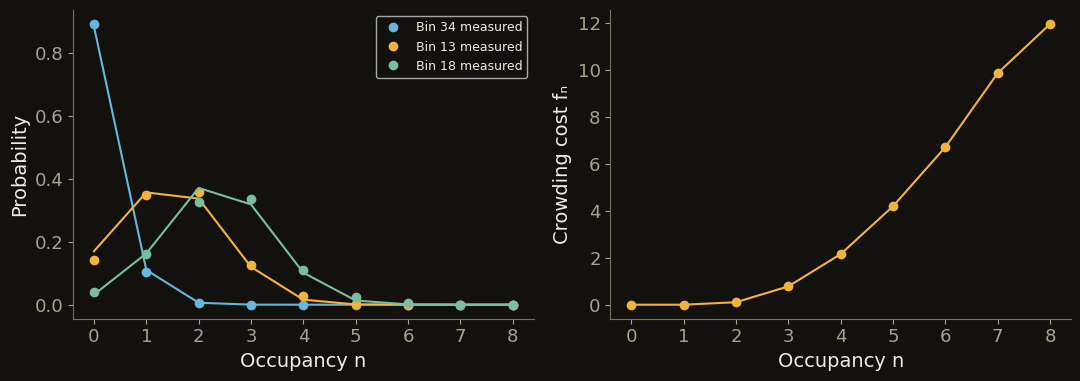

In [28]:
def fit_dfft(occupancies):
    a=np.asarray(occupancies,int);T,B=a.shape;nmax=int(a.max());n=np.arange(nmax+1)
    histogram=np.stack([np.bincount(a[:,b],minlength=nmax+1) for b in range(B)])
    mean=a.mean(axis=0)
    def objective(parameters):
        f=np.r_[0.,0.,parameters[:nmax-1]];V=parameters[nmax-1:]
        logw=-f[None,:]-V[:,None]*n-gammaln(n+1)
        logz=logsumexp(logw,axis=1)
        p=np.exp(logw-logz[:,None])
        loss=(T*logz.sum()+(histogram*(f[None,:]+V[:,None]*n+gammaln(n+1))).sum())/(T*B)
        grad_f=(histogram.sum(axis=0)-T*p.sum(axis=0))[2:]/(T*B)
        grad_v=(T*mean-T*(p@n))/(T*B)
        return loss,np.r_[grad_f,grad_v]
    initial=np.r_[np.zeros(nmax-1),-np.log(np.maximum(mean,1e-8))]
    opt=minimize(objective,initial,jac=True,method='L-BFGS-B',options={'maxiter':2500,'gtol':1e-9,'ftol':1e-12})
    if not opt.success: raise RuntimeError(opt.message)
    return np.r_[0.,0.,opt.x[:nmax-1]],opt.x[nmax-1:],float(opt.fun)

split=int(.8*len(rect))
f_rect,V_rect,train_nll=fit_dfft(rect[:split])
prob_rect=count_probabilities(f_rect,V_rect)
observed_prob=np.stack([np.bincount(rect[:,b],minlength=len(f_rect))/len(rect) for b in range(rect.shape[1])])
held=rect[split:]
# The baseline uses the full Poisson law; DFFT uses its declared measured count support.
lam=rect[:split].mean(axis=0)
poisson_log=held*np.log(lam)-lam-gammaln(held+1)
dfft_log=np.log(np.maximum(prob_rect[np.arange(held.shape[1])[None,:],held],1e-300))
ll_gain=float(np.mean(dfft_log-poisson_log))
assert np.isfinite(ll_gain)
print({'held_out_gain_nats_per_bin_observation':round(ll_gain,4),'training_occupancy_range':[0,len(f_rect)-1]})
fig,ax=plt.subplots(1,2,figsize=(11,4))
chosen=np.argsort(rect.mean(axis=0))[[10,25,40]]
n=np.arange(len(f_rect))
for b,c in zip(chosen,[COLORS['blue'],COLORS['amber'],COLORS['green']]):
    ax[0].plot(n,observed_prob[b],'o',color=c,label=f'Bin {b+1} measured')
    ax[0].plot(n,prob_rect[b],color=c)
ax[0].set(xlabel='Occupancy n',ylabel='Probability',xticks=n);ax[0].legend(fontsize=9)
ax[1].plot(n,f_rect,'o-',color=COLORS['amber']);ax[1].set(xlabel='Occupancy n',ylabel='Crowding cost fₙ',xticks=n)
plt.tight_layout();plt.show()

### Remove location preference to expose the shared curvature

HTML slide 64.

$$-\ln[n!p_b(n)]=f_n+(V_b-\mu_{\rm occ})n+\ln\mathcal Z_b.$$

The rectangle fit absorbs $\mu_{\rm occ}$ into the location costs. Subtracting each bin's fitted line leaves an estimate of the shared nonlinear crowding cost. Empty histogram values are omitted from the logarithmic display.

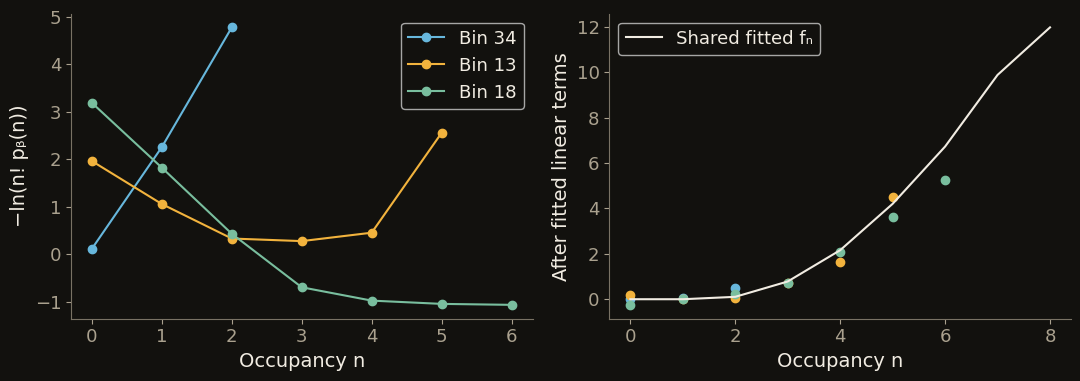

In [29]:
logz=logsumexp(-f_rect[None,:]-V_rect[:,None]*n-gammaln(n+1),axis=1)
pseudo=-np.log(np.where(observed_prob>0,observed_prob,np.nan))-gammaln(n+1)
collapsed=pseudo-V_rect[:,None]*n-logz[:,None]
fig,ax=plt.subplots(1,2,figsize=(11,4))
for b,c in zip(chosen,[COLORS['blue'],COLORS['amber'],COLORS['green']]):
    ax[0].plot(n,pseudo[b],'o-',color=c,label=f'Bin {b+1}')
    ax[1].plot(n,collapsed[b],'o',color=c)
ax[1].plot(n,f_rect,color=COLORS['ink'],label='Shared fitted fₙ')
ax[0].set(xlabel='Occupancy n',ylabel='−ln(n! pᵦ(n))');ax[1].set(xlabel='Occupancy n',ylabel='After fitted linear terms');ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()

### From bin counts to a density field

HTML slides 68–69. Divide a bin count by its physical area: $\rho(\mathbf x_b,t)\simeq N_b(t)/A_b$. The field retains spatial variation while dropping individual identities.

The local crowding and environment contribution is

$$\mathcal H_{\rm DFFT}[\rho]=\int[f_{\rm loc}(\rho)+V_{\rm env}(\mathbf x)\rho]d^2x.$$

The illustration uses $f_{\rm loc}(\rho)=g\rho^2/2$. The next calculation adds counting entropy to form the full occupancy functional.

In [30]:
def density_functional(rho,V,area=1.,crowding=1.):
    rho=np.asarray(rho,float);V=np.asarray(V,float)
    environment=float(area*np.dot(V,rho))
    interaction=float(.5*area*crowding*np.dot(rho,rho))
    return dict(environment=environment,interaction=interaction,total=environment+interaction)

profile_x=np.linspace(0,1,48)
profile_V=3*profile_x
profile_flat=np.full(48,2.)
profile_biased=np.exp(-profile_V);profile_biased*=96/profile_biased.sum()
assert np.isclose(profile_flat.sum(),profile_biased.sum())
packet['functional']={'x':profile_x,'V':profile_V,'flat':profile_flat,'biased':profile_biased}

### Balance preference against crowding at fixed population

HTML slides 69–71. For a smooth density profile, the counting factor contributes the ideal term:

$$\mathcal G_{\rm occ}[\rho]=\int\left[\rho\left(\ln\frac{\rho}{\rho_{\rm ref}}-1\right)+f_{\rm loc}(\rho)+V_{\rm env}\rho\right]d^2x.$$

Minimizing at fixed $\int\rho\,d^2x=N$ requires equal marginal cost everywhere:

$$\ln\frac{\rho}{\rho_{\rm ref}}+f'_{\rm loc}(\rho)+V_{\rm env}=\mu_{\rm occ}.$$

For $f_{\rm loc}=g\rho^2/2$, the extra crowding cost is $g\rho$. Increasing $g$ flattens the profile; the multiplier adjusts to conserve the population. This demonstration uses dimensionless density in equal-area model cells. The discrete fly prediction sums count probabilities and does not use this smooth-density approximation.

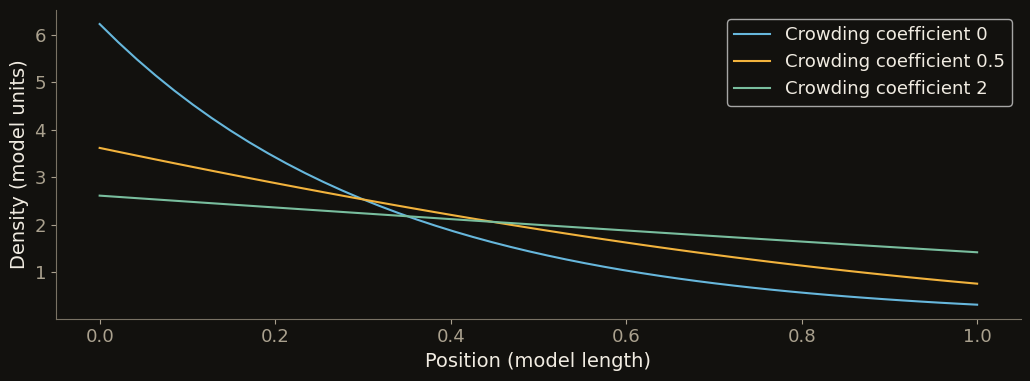

In [31]:
def density_profile(potential,total=96.,crowding=.5):
    potential=np.asarray(potential,float)
    def at_mu(mu):
        target=mu-potential
        log_rho=np.minimum(target, np.log(np.maximum(np.abs(target)+1,1)/max(crowding,1e-12))) if crowding>0 else target.copy()
        for _ in range(60):
            rho=np.exp(log_rho)
            log_rho-=(log_rho+crowding*rho-target)/(1+crowding*rho)
        return np.exp(log_rho)
    mu=brentq(lambda value:at_mu(value).sum()-total,-30,50)
    return at_mu(mu),mu

profile_coordinate=np.linspace(0,1,48);potential=3*profile_coordinate
fig,ax=plt.subplots()
for g,color in [(0.,COLORS['blue']),(.5,COLORS['amber']),(2.,COLORS['green'])]:
    density,mu=density_profile(potential,crowding=g)
    assert np.isclose(density.sum(),96.)
    assert np.allclose(np.log(density)+g*density+potential,mu,atol=1e-10)
    ax.plot(profile_coordinate,density,color=color,label=f'Crowding coefficient {g:g}')
ax.set(xlabel='Position (model length)',ylabel='Density (model units)');ax.legend();plt.tight_layout();plt.show()


### Transfer the measured crowding cost to a new chamber

HTML slides 65–67. The crowded rectangle supplies $f_n$. Two flies supply the preference in the C-shaped chamber; its 189-fly distribution is reserved for the prediction test.

Transfer at equal physical density, using $f_n\simeq A f_{\rm loc}(n/A)$:

$$a=\frac{A_{\rm new}}{A_{\rm old}},\qquad f_{\rm new}(n)=a f_{\rm old}(n/a).$$

The bin areas are 0.1493 cm² (rectangle) and 0.3514 cm² (C-shaped). Keep interpolation within the supported density range, infer the new location costs from sparse occupancy, and choose one multiplier so the predicted total is 189.

{'C_chamber_naive_RMSE_flies_per_bin': 3.657, 'C_chamber_DFFT_RMSE': 1.2, 'mu': 5.495}


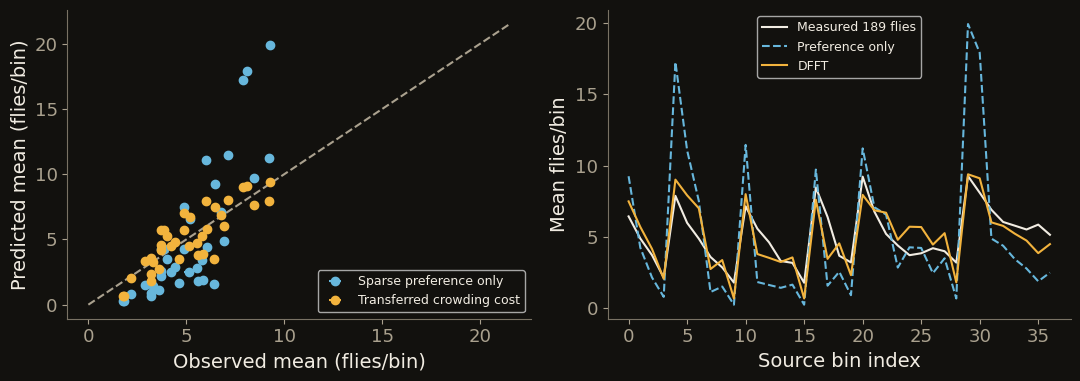

In [32]:
def rescale_cost(f,area_old,area_new):
    ratio=area_new/area_old
    n_new=np.arange(int(np.floor((len(f)-1)*ratio))+1)
    values=CubicSpline(np.arange(len(f))*ratio,np.asarray(f)*ratio)(n_new)
    # The spline arguments already include both area rescalings; remove its linear gauge.
    return values-values[0]-n_new*(values[1]-values[0])

def infer_preference_from_mean(f,means):
    return np.array([brentq(lambda V:count_mean(f,[V])[0]-m,-60,60) for m in means])

def predict_total(f,V,total):
    mu=brentq(lambda value:count_mean(f,V,value).sum()-total,-60,60)
    return count_mean(f,V,mu),float(mu)

f_c=rescale_cost(f_rect,areas['rectangle'],areas['c_shape'])
V_c=infer_preference_from_mean(f_c,c_low.mean(axis=0))
pred_c,mu_c=predict_total(f_c,V_c,189)
naive_c=189*c_low.mean(axis=0)/c_low.sum(axis=1).mean()
obs_c=c_high.mean(axis=0)
blocks=np.array_split(c_high,8)
sem_c=np.std([b.mean(axis=0) for b in blocks],axis=0,ddof=1)/np.sqrt(8)
rmse_naive=float(np.sqrt(np.mean((naive_c-obs_c)**2)))
rmse_dfft=float(np.sqrt(np.mean((pred_c-obs_c)**2)))
assert np.isclose(pred_c.sum(),189)
print({'C_chamber_naive_RMSE_flies_per_bin':round(rmse_naive,3),'C_chamber_DFFT_RMSE':round(rmse_dfft,3),'mu':round(mu_c,3)})
fig,ax=plt.subplots(1,2,figsize=(11,4))
maxn=max(obs_c.max(),naive_c.max())*1.08
ax[0].errorbar(obs_c,naive_c,xerr=sem_c,fmt='o',color=COLORS['blue'],label='Sparse preference only')
ax[0].errorbar(obs_c,pred_c,xerr=sem_c,fmt='o',color=COLORS['amber'],label='Transferred crowding cost')
ax[0].plot([0,maxn],[0,maxn],ls='--',color=COLORS['muted']);ax[0].set(xlabel='Observed mean (flies/bin)',ylabel='Predicted mean (flies/bin)');ax[0].legend(fontsize=9)
ax[1].plot(obs_c,color=COLORS['ink'],label='Measured 189 flies');ax[1].plot(naive_c,color=COLORS['blue'],ls='--',label='Preference only');ax[1].plot(pred_c,color=COLORS['amber'],label='DFFT');ax[1].set(xlabel='Source bin index',ylabel='Mean flies/bin');ax[1].legend(fontsize=9);plt.tight_layout();plt.show()

### Test the same procedure in a square chamber

HTML slide 67. One fly supplies the sparse preference; the crowded recording contains about 125 flies in 49 bins. The prediction uses nominal total 125, the new sparse preference, and the same rectangle-derived crowding cost after area conversion.

Square mean-density comparison: {'rmse_naive': 1.979, 'rmse_dfft': 0.775, 'mean_detected_total': 124.019}


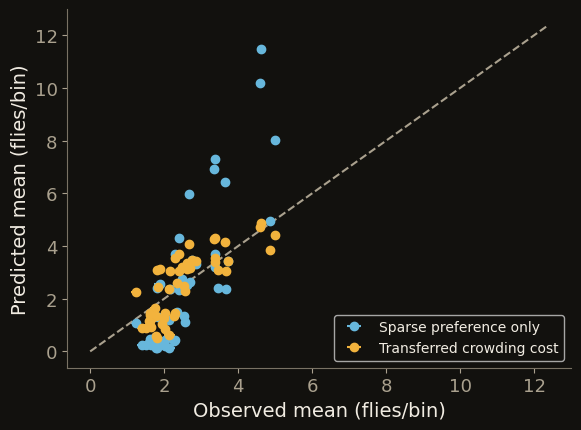

In [33]:
f_square=rescale_cost(f_rect,areas['rectangle'],areas['square'])
V_square=infer_preference_from_mean(f_square,square_low.mean(axis=0))
pred_square,mu_square=predict_total(f_square,V_square,125)
naive_square=125*square_low.mean(axis=0)
obs_square=square_high.mean(axis=0)
square_sem=np.std([b.mean(axis=0) for b in np.array_split(square_high,8)],axis=0,ddof=1)/np.sqrt(8)
square_result={'f':f_square,'V':V_square,'mu':mu_square,'predicted':pred_square,'naive':naive_square,
 'observed':obs_square,'sem':square_sem,'sparse_mean':square_low.mean(axis=0),'nominal_total':125,
 'mean_detected_total':float(square_high.sum(axis=1).mean()),
 'rmse_naive':float(np.sqrt(np.mean((naive_square-obs_square)**2))),
 'rmse_dfft':float(np.sqrt(np.mean((pred_square-obs_square)**2)))}
assert np.isclose(pred_square.sum(),125)
print('Square mean-density comparison:', {k:round(square_result[k],3) for k in ['rmse_naive','rmse_dfft','mean_detected_total']})
fig,ax=plt.subplots(figsize=(6,4.5))
ax.errorbar(obs_square,naive_square,xerr=square_sem,fmt='o',color=COLORS['blue'],label='Sparse preference only')
ax.errorbar(obs_square,pred_square,xerr=square_sem,fmt='o',color=COLORS['amber'],label='Transferred crowding cost')
limit=max(naive_square.max(),obs_square.max())*1.08
ax.plot([0,limit],[0,limit],'--',color=COLORS['muted']);ax.set(xlabel='Observed mean (flies/bin)',ylabel='Predicted mean (flies/bin)');ax.legend(fontsize=10);plt.tight_layout();plt.show()

### Compare predictions with the crowded measurements

HTML slides 66–68. Show preference-only prediction, prediction with crowding, and measurement on a common scale. The scatter plots compare predicted and observed means; the diagonal denotes exact agreement. Horizontal intervals are SEMs across eight contiguous observation blocks. The exported mean-density RMSEs are 3.66 versus 1.20 flies/bin in the C-shaped chamber and 1.98 versus 0.78 in the square. The replay uses source observation number.

In [34]:
from scipy.ndimage import zoom

def small_bin_map(path,variable,max_side=150):
    a=loadmat(path)[variable]
    step=max(1,int(np.ceil(max(a.shape)/max_side)))
    return a[::step,::step].astype(int)

packet['flies']={'f':f_rect,'V_rectangle':V_rect,'observed_probability':observed_prob,'probability':prob_rect,
                 'pseudo':pseudo,'collapsed':collapsed,'chosen_bins':chosen,'rectangle_means':rect.mean(axis=0),
                 'rectangle_counts':rect[::25], 'rectangle_mask':small_bin_map(fly_dir/'figure-03-rectangle-bins.mat','bins_f'),
                 'c_mask':small_bin_map(fly_dir/'figure-03-c-shape-bins.mat','bins'),
                 'c_sparse_mean':c_low.mean(axis=0),'c_observed':obs_c,'c_naive':naive_c,'c_predicted':pred_c,'c_sem':sem_c,
                 'c_f':f_c,'c_V':V_c,'c_mu':mu_c,'areas_cm2':areas,'held_out_gain':ll_gain,
                 'rmse_naive':rmse_naive,'rmse_dfft':rmse_dfft,'count_support':[0,len(f_rect)-1]}
square_result['mask']=small_bin_map(fly_dir/'figure-03-square-bins.mat','bins')
packet['flies']['square']=square_result

## From stationary density to active dynamics

HTML slide 72. The following active-matter preview remains in the companion. In the absence of births and deaths, density obeys

$$\partial_t\rho+\nabla\cdot\mathbf j=0.$$

$\mathbf j$ is number current (animals per length per time in two dimensions). Conservation is exact; the current requires a model of movement. The fitted stationary fly distribution alone does not specify that current. Lecture 16 introduces persistent self-propulsion and how collisions can suppress escape from dense regions. Lecture 17 adds orientational fields for rods and develops nematic order from the beginning.

## Additional comparison: a stationary midge swarm

This measured dataset is retained for further exploration. It is outside the main HTML lecture sequence.

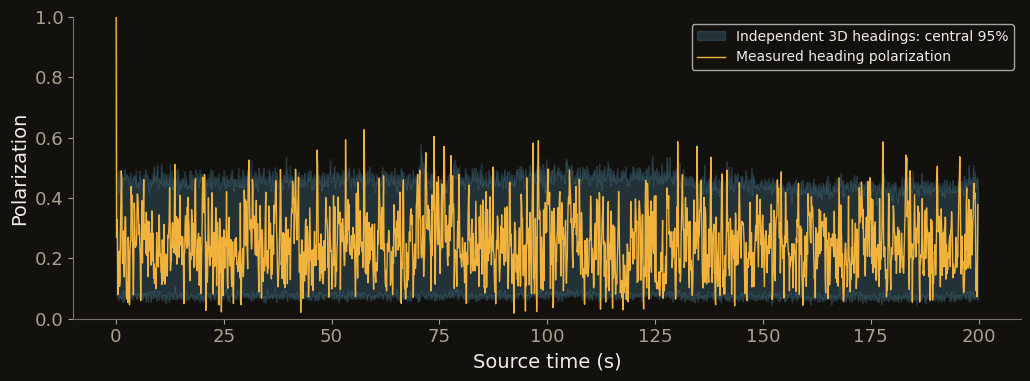

In [35]:
midges=np.loadtxt(DATA/'insect-swarms/midge-ob11.txt',delimiter=',')
frame_times,frame_start,frame_count=np.unique(midges[:,4],return_index=True,return_counts=True)
# Source rows are grouped by track, so build explicit time groups rather than using frame_start.
by_time=np.argsort(midges[:,4],kind='stable');sorted_midges=midges[by_time]
mt,starts,counts=np.unique(sorted_midges[:,4],return_index=True,return_counts=True)
selected=np.arange(0,len(mt),10)
midge_frames=[];midge_stats=[]
for k in selected:
    rows=sorted_midges[starts[k]:starts[k]+counts[k]]
    pos=rows[:,[1,3,2]];vel=rows[:,[5,7,6]]
    stats=order_parameters(pos,vel)
    n=stats['count']
    null=rng.normal(size=(300,n,3));null/=np.linalg.norm(null,axis=-1,keepdims=True)
    null_phi=np.linalg.norm(null.mean(axis=1),axis=1)
    midge_frames.append({'time':float(mt[k]),'rows':np.column_stack((rows[:,0],pos,vel))})
    midge_stats.append([mt[k],stats['phi'],stats['phi_v'],n,*np.quantile(null_phi,[.025,.5,.975])])
midge_stats=np.array(midge_stats)
packet['midges']={'frames':midge_frames[::2], 'stats':midge_stats,'units':'mm, s','source':'Ob11','identity':'track fragments'}
fig,ax=plt.subplots();ax.fill_between(midge_stats[:,0],midge_stats[:,4],midge_stats[:,6],color=COLORS['blue'],alpha=.2,label='Independent 3D headings: central 95%');ax.plot(midge_stats[:,0],midge_stats[:,1],color=COLORS['amber'],lw=1,label='Measured heading polarization');ax.set(xlabel='Source time (s)',ylabel='Polarization',ylim=(0,1));ax.legend(fontsize=10);plt.tight_layout();plt.show()

## Numerical checks and browser export

Compare deterministic calculations in Python and JavaScript, then export the prepared data used by the HTML lecture.

In [36]:
fixtures={
 'order':{'positions':example_p,'velocities':example_v,'expected':order_parameters(example_p,example_v)},
 'body':{'displacement':np.array([[3.,4.],[-2.,1.]]),'velocity':np.array([[0.,2.],[3.,4.]])},
 'count':{'f':np.array([0.,0.,.2,.7,1.6,3.]),'V':np.array([-1.,0.,1.]),'mu':.3},
 'wave':{'angle':np.array([0.,.2,.4,.1,-.1]),'rate':np.array([.1,0.,-.1,0.,.05]),'dt':.004,'dx':.125},
 'rule':{'x':40.,'y':25.,'delta':.4,'alignment':1.2,'attraction':.8,'repulsion':1.5},
}
fixtures['body']['expected']=body_coordinates(fixtures['body']['displacement'],fixtures['body']['velocity'])
fixtures['count']['expected']=count_probabilities(fixtures['count']['f'],fixtures['count']['V'],fixtures['count']['mu'])
for model in ['wave','diffusion']:
    fixtures['wave'][model]=propagation_step(fixtures['wave']['angle'],fixtures['wave']['rate'],.004,.125,model=model)
fixtures['rule']['expected']=interaction_rule(**{k:fixtures['rule'][k] for k in ['x','y','delta','alignment','attraction','repulsion']})
fixtures['pair']={'position':np.array([[55.,2.],[0.,0.]]),'heading':np.array([.2,0.]),'speed':np.array([50.,48.]),'time':1.,'dt':.01}
for mode in ['alignment','position']:
    fixtures['pair'][mode+'_expected']=pair_model_step(fixtures['pair']['position'],fixtures['pair']['heading'],fixtures['pair']['speed'],1.,.01,mode)
fixtures['functional']={'rho':np.array([1.,2.,3.]),'V':np.array([0.,1.,2.]),'area':.5,'crowding':.3}
fixtures['functional']['expected']=density_functional(**fixtures['functional'])
fixtures['relaxation']={'angle':.4,'target':-.1,'dt':.03,'tau_relax':.2}
fixtures['relaxation']['expected']=relaxation_step(**fixtures['relaxation'])
fixtures['tracking']={'tau_relax':.35,'tau_network':.5,'dt':.1}
fixtures['tracking']['expected']=changing_neighbors(**fixtures['tracking'])
fixtures['extended']={
 'triplet':triplet_prediction(pair_example),
 'informed':informed_heading_step(heading_start,.2,1.3,.8,.03),
 'sensing':sensing_step(np.array([-20.,4.,.3]),3.,.02,12.,4.),
 'landscape':marching_landscape(.6,1.,.04),
 'choice':choice_potential(np.array([-.8,0.,.8]),.7,4.),
 'kernel':ring_kernel(24,1.2,.7),
 'canonical':canonical_counts(6,(.7,0.,0.),.4)[:2],
 'profile':density_profile(np.linspace(0,3,48),96.,.5),
 'dispersion':[[v.real.tolist(),v.imag.tolist()] for v in wave_dispersion(np.array([0.,.1,.5,1.]),2.,.7)]
}
packet['validation']=fixtures

def json_ready(value):
    if isinstance(value,np.ndarray):return json_ready(value.tolist())
    if isinstance(value,(np.floating,float)):return round(float(value),6) if np.isfinite(value) else None
    if isinstance(value,np.integer):return int(value)
    if isinstance(value,dict):return {str(k):json_ready(v) for k,v in value.items()}
    if isinstance(value,(tuple,list)):return [json_ready(v) for v in value]
    return value

# Fixtures retain full precision; scientific display/replay payloads use six decimal places.
fixture_path=OUT/'lecture-15-validation.json'
def precise(value):
    if isinstance(value,np.ndarray):return value.tolist()
    if isinstance(value,(np.integer,np.floating)):return value.item()
    if isinstance(value,dict):return {k:precise(v) for k,v in value.items()}
    if isinstance(value,(tuple,list)):return [precise(v) for v in value]
    return value
fixture_path.write_text(json.dumps(precise(fixtures),indent=2,allow_nan=False)+'\n')
packet['summary']={'fish_encounters':len(enc),'fish_test_trials':10,'dfft_heldout_gain':ll_gain,
                   'c_rmse_naive':rmse_naive,'c_rmse_dfft':rmse_dfft,'square_rmse_naive':square_result['rmse_naive'],'square_rmse_dfft':square_result['rmse_dfft']}
output=OUT/'lecture-15-browser-data.js'
output.write_text('/* Generated by the executed Lecture 15 Python companion. */\nwindow.LECTURE15_DATA='+json.dumps(json_ready(packet),separators=(',',':'),allow_nan=False)+';\n')
print(f'Browser dataset written ({output.stat().st_size/1e6:.2f} MB).')
print('Normalization, observed totals, normal-acceleration orthogonality and deterministic fixtures checked.')
# Reproducible provenance for the browser payload; code-cell hash excludes saved outputs.
import hashlib
import importlib.metadata
import nbformat
companion=ROOT/'lectures/lecture-15-animal-interaction-rules.ipynb'
source_nb=nbformat.read(companion,4)
code_sources='\n\n'.join(c.source for c in source_nb.cells if c.cell_type=='code')
inputs=[DATA/'flocking/fish-pairs-2021.npz',DATA/'insect-swarms/midge-ob11.txt',fly_dir/'physical-bin-areas.json']
inputs+=sorted(fly_dir.glob('*.mat'))
manifest={'companion':str(companion.relative_to(ROOT)),'code_cells_sha256':hashlib.sha256(code_sources.encode()).hexdigest(),
 'inputs':[{ 'path':str(p.relative_to(ROOT)), 'bytes':p.stat().st_size,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in inputs],
 'browser_payload':{'path':str(output.relative_to(ROOT)),'bytes':output.stat().st_size,'sha256':hashlib.sha256(output.read_bytes()).hexdigest(),'precision_decimal_places':6},
 'versions':{name:importlib.metadata.version(name) for name in ['numpy','scipy','pandas','matplotlib','nbformat']},
 'summary':json_ready(packet['summary']),
 'interpretation':{'fish':'Trial-held-out conditional prediction; source identities are local to each sheet. Focal identity comparison uses trial 1 only.',
 'fly_transfer':'Shared nonparametric cost from rectangle first 80%; C-sparse bin means determine V; physical area rescaling follows author script; C-crowded data only evaluate prediction.',
 'fly_uncertainty':'SEM of eight contiguous observation blocks; no claim of biological replication or independent time samples.',
 'movie':'Golden-shiner experimental footage has no verified matching trajectory file; quantitative fish responses use the separate pair dataset.',
 'local_alignment':'Mora published starling results motivate deterministic local-mode illustrations; no new Mora parameter fit is claimed.'}}
(OUT/'lecture-15-data-manifest.json').write_text(json.dumps(manifest,indent=2,allow_nan=False)+'\n')
print('Input hashes, code-source hash, package versions and processing manifest recorded.')


Browser dataset written (2.48 MB).
Normalization, observed totals, normal-acceleration orthogonality and deterministic fixtures checked.


Input hashes, code-source hash, package versions and processing manifest recorded.


## Readings

- [Katz et al. (2011)](https://doi.org/10.1073/pnas.1107583108): fish pair and triplet responses.
- [Couzin et al. (2011)](https://doi.org/10.1126/science.1210280): uninformed fish and collective decisions.
- [Berdahl et al. (2013)](https://doi.org/10.1126/science.1225883): collective environmental sensing.
- [Sayin et al. (2025)](https://doi.org/10.1126/science.adq7832): field and virtual-reality locust experiments.
- [Mora et al. (2016)](https://doi.org/10.1038/nphys3846): dynamical inference and local relaxation.
- [Attanasi et al. (2014)](https://doi.org/10.1038/nphys3035): propagation of collective turns.
- [Méndez-Valderrama et al. (2018)](https://doi.org/10.1038/s41467-018-05750-z): occupancy fluctuations and density prediction.